# Benchmark: old StarSim vs optimized SunSim — circular active regions

Both versions simulate the same star with the same **circular active regions** (spots and faculae with a position, a radius and a lifetime), in **photometry** (light curve) and in **RV mode** (CCF and its RV, FWHM, BIS, contrast). The time of every step is measured for several simulations, and the outputs of the two versions are compared. Section 12 does the same with the 2D maps (89 real SDO epochs). Section 11 then explores every parameter (inclination, latitude, radii, contrast, rotation, differential rotation, lifetime, rings, planets), from usual to extreme values, with the optimized version only.

| | old version | optimized version |
|---|---|---|
| code | `starsim` package installed in `env_sunsim` (`/Users/sophiestucki/starsim`) | the `sunsim` package (`sunsim/simulation.py`, `flux_grid.py`, `ccf_grid.py`, `active_region.py`, ...) |
| set-up | a `.conf` file (`StarSim(conf_file_path)`) and the spot map | Python objects |
| spectra and grids | read and built again at every `compute_forward` | built once, reused by every simulation |
| time series | Python loop over the epochs (one Numba call per epoch) | one parallel Numba call for all the epochs |
| CCF parameters | `scipy.curve_fit` for every CCF | parallel Numba fit |

**Steps that are timed**

| old version | optimized version |
|---|---|
| `init`: `StarSim(conf)` | `spectra`: read the MURaM spectra |
| `photometry`: `compute_forward(['lc'])` (includes reading the spectra and building the grids) | `grids`: photometric flux grids and CCF grids |
| `rv`: `compute_forward(['rv', 'bis', 'fwhm', 'contrast'])` (idem) | `simulation`: `StarSim` + `generate_timeseries` (light curve and CCFs together); inside it, `geometry`, `timeseries` and `ccf_params` |

Since the old code reads the spectra and builds its grids inside every `compute_forward`, one **complete simulation** is compared: old = `init + photometry + rv`, optimized = `spectra + grids + simulation`. The optimized version can also reuse its spectra and grids for many simulations (other regions, epochs, planets): the time of `simulation` alone is given too.

**Same physics in both.** The optimized version is set up from the same `.conf` file and the same input files as the old one:
* the same MURaM spectra (folder `mps_spectra_folder` of the old code) for the quiet photosphere and the faculae, spot spectra = quiet × black-body ratio at `T - spot_T_contrast`;
* the same filter, CCF mask (with the same line weights), velocity grid, number of rings, rotation (and differential rotation), inclination and radius;
* the CCF of every ring is the disc-centre CCF of the surface weighted by the brightness of the ring (`mu_ratio` of `CCF_grid`, as the old code weights it); the quiet and facular CCFs keep their bisector and the spot CCF has its bisector removed (`remove_bis_spot = 1` of the old `mps` mode);
* the same regions, with the same appearance time and lifetime.

In [1]:
import os
os.environ.setdefault('KMP_WARNINGS', '0')   # before numpy: silences the OpenMP 'omp_set_nested deprecated' info
import io, sys, time, shutil, tempfile, platform, contextlib
from configparser import ConfigParser
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import numba

# optimized version (the sunsim package; REPO = the folder of the repository)
import sunsim
REPO = os.path.dirname(os.path.dirname(os.path.abspath(sunsim.__file__)))
from sunsim import StarSim
from sunsim import flux_grid
from sunsim import CCF_grid
from sunsim import active_region
from sunsim import black_body

# old version (installed package)
import starsim as old_starsim
from starsim import StarSim as OldStarSim

print('machine : %s, %d CPUs | numba %s (%d threads)' % (platform.platform(), os.cpu_count(), numba.__version__, numba.get_num_threads()))
print('old starsim %s from %s' % (old_starsim.__version__, os.path.dirname(old_starsim.__file__)))

machine : macOS-26.6.2-arm64-arm-64bit, 10 CPUs | numba 0.62.1 (10 threads)
old starsim 3.0.1 from /Users/sophiestucki/starsim/starsim


## 1. Settings

* `old_conf_template`: `.conf` file of the old code used as template (the benchmark only changes what is listed in section 2);
* `mps_folder`: folder with the MURaM spectra: `av_solar_ssd_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy`, `..._high_res_grid_cleaned.npy` and the same two for `av_solar_faculae_200G`;
* `n_epochs` epochs over one rotation;
* `cases`: the simulations. Every region is `(type, radius [deg], colatitude [deg], longitude [deg], appearance time [d], lifetime [d])`, type `'sp'` (spot) or `'fc'` (facula); every case has its number of rings. The default cases:

| case | regions | rings |
|---|---|---|
| `1 spot` | spot of radius 10° on the equator, longitude 180° (crosses the disc centre at P/2) | 15 |
| `1 facula` | facula of radius 10° at the same position | 15 |
| `spot + facula, decentred` | spot of 8° and facula of 14°, the centre of the facula displaced by 10° in longitude: the spot sticks out of the facula on one side | 15 |
| `several latitudes` | three spot + facula pairs (7° and 12°) at colatitude 60°, 90°, 120° (latitude +30°, 0°, −30°) and longitude 165°, 180°, 195° | 15 |
| `1 facula, 30 rings` | the facula of `1 facula` with a finer grid | 30 |

**Running time.** The old RV mode takes about 2 minutes per simulation (100 epochs), so the whole notebook takes about 10-12 minutes with the default cases.

In [2]:
old_package = os.path.dirname(old_starsim.__file__)
old_conf_template = os.path.join(old_package, 'conf', 'starsim_sun_sdo_mps_lowres.conf')
mps_folder = os.path.join(old_package, 'MPS-ATLAS_spectra') + '/'
ccf_mask = os.path.join(old_package, 'masks', 'HARPS_G20_mps_friendly.mas')

n_epochs = 100

# every region: (type, radius [deg], colatitude [deg], longitude [deg], appearance time [d], lifetime [d])
several_latitudes = []
for colat, lon in [(60, 165), (90, 180), (120, 195)]:          # latitude +30, 0, -30 deg
    several_latitudes += [('sp', 7, colat, lon, 0.0, 1000.0), ('fc', 12, colat, lon, 0.0, 1000.0)]

cases = {                                                       # name: (number of rings, regions)
    '1 spot':                       (15, [('sp', 10, 90, 180, 0.0, 1000.0)]),
    '1 facula':                     (15, [('fc', 10, 90, 180, 0.0, 1000.0)]),
    'spot + facula, decentred':     (15, [('sp', 8, 90, 180, 0.0, 1000.0), ('fc', 14, 90, 190, 0.0, 1000.0)]),
    'several latitudes':            (15, several_latitudes),
    '1 facula, 30 rings':           (30, [('fc', 10, 90, 180, 0.0, 1000.0)]),
}
comparison_case = 'spot + facula, decentred'   # case whose outputs are plotted in section 7

work_dir = tempfile.mkdtemp(prefix='sunsim_benchmark_')
print('temporary folder (configuration files):', work_dir)

temporary folder (configuration files): /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/sunsim_benchmark_2k3kbxx1


## 2. Configuration of the old version

For every number of rings, the template is read and these values are set: `simulation_mode = grid`, `n_grid_rings`, `spectral_library = mps`, `mps_spectra_folder`, CCF with the mask `ccf_mask`, no map mode (`sdo_input = 0`), no plots (`plot_grid_map = 0`), no planet, regions of constant radius (`spots_evo_law = constant`), and `limb_extrapolation = linear`: below `limb_lim = 0.1` (the smallest tabulated μ) the intensity is I(μ) = μ / 0.1 · I(0.1), as in the optimized version (the template has `constant`, I(μ) = I(0.1)). Everything else (star, rotation, limb darkening, filter, RV grid, line weights) comes from the template.

The old code always reads its regions from `spotmap.dat` in its package folder. To leave that file untouched, the regions of every case are given to the old object after it is created (`spot_map`, `active_region_types`, as `StarSim.__init__` sets them from the file).

In [3]:
def old_conf(n_rings):
    """Write the configuration of the old version for n_rings rings and return its path."""
    conf = ConfigParser(inline_comment_prefixes='#')
    conf.read(old_conf_template)
    conf.set('general', 'simulation_mode', 'grid')
    conf.set('general', 'n_grid_rings', str(n_rings))
    conf.set('general', 'spectral_library', 'mps')
    conf.set('general', 'mps_spectra_folder', mps_folder)
    conf.set('rv', 'ccf_template', 'mask')
    conf.set('rv', 'ccf_mask', ccf_mask)
    conf.set('spots', 'sdo_input', '0')
    conf.set('spots', 'plot_grid_map', '0')
    conf.set('spots', 'spots_evo_law', 'constant')
    conf.set('planet', 'simulate_planet', '0')
    conf.set('LD', 'limb_extrapolation', 'linear')     # below limb_lim: I(mu) = mu / limb_lim * I(limb_lim), as flux_grid
    path = os.path.join(work_dir, 'benchmark_N%d.conf' % n_rings)
    with open(path, 'w') as f:
        conf.write(f)
    return path, conf

def old_spot_map(regions):
    """Regions -> rows of the old spot map: type (0 spot, 1 facula), appearance, lifetime, colatitude, longitude, radius,
    0, 0 (sorted by type, spots first, as the old StarSim does)."""
    rows = np.array([[0.0 if typ == 'sp' else 1.0, t0, life, colat, lon, r, 0.0, 0.0]
                     for typ, r, colat, lon, t0, life in regions])
    return rows[np.argsort(rows[:, 0], kind='stable')]

_, conf = old_conf(15)
for section, keys in (('star', ['temperature_photosphere', 'spot_T_contrast', 'rotation_period', 'radius', 'inclination', 'differential_rotation']),
                      ('general', ['wavelength_lower_limit', 'wavelength_upper_limit', 'ccf_norm', 'flux_flat']),
                      ('rv', ['ccf_rv_range', 'ccf_rv_step', 'ccf_weight_lines']), ('files', ['filter_name']),
                      ('spots', ['reference_time'])):
    print('[%s] ' % section + ', '.join('%s = %s' % (k, conf.get(section, k)) for k in keys))

[star] temperature_photosphere = 5778.0, spot_T_contrast = 400.0, rotation_period = 25.05, radius = 1, inclination = 90.0, differential_rotation = 0
[general] wavelength_lower_limit = 3801.0, wavelength_upper_limit = 7999.0, ccf_norm = 0, flux_flat = 0
[rv] ccf_rv_range = 18.0, ccf_rv_step = 0.25, ccf_weight_lines = 1
[files] filter_name = TJO_R.dat
[spots] reference_time = 0.0


## 3. Timer

`timer(case, version, step)` stores the time of every step in `timings`. The old code prints its progress and shows a plot of every bisector it fits; `quiet_old()` hides both while it runs (the plots are closed without being drawn).

In [4]:
timings = []

class timer:
    """with timer(case, 'old', 'rv'): ...  -> timings gets (case, version, step, seconds)."""
    def __init__(self, case, version, step):
        self.case, self.version, self.step = case, version, step
    def __enter__(self):
        self.t0 = time.perf_counter()
    def __exit__(self, *args):
        record(self.case, self.version, self.step, time.perf_counter() - self.t0)

def record(case, version, step, seconds):
    timings.append({'case': case, 'version': version, 'step': step, 'time [s]': seconds})
    print('%-26s %-10s %-12s %9.2f s' % (case, version, step, seconds))

@contextlib.contextmanager
def quiet_old():
    """Hide the prints and the debug plots (plt.show) of the old code."""
    show = plt.show
    plt.show = lambda *args, **kwargs: None
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            yield
    finally:
        plt.show = show
        plt.close('all')

## 4. Old version

For every case: `StarSim(conf)`, the regions, then `compute_forward` for the light curve and for the CCFs.

In [5]:
P_rot = conf.getfloat('star', 'rotation_period')
times = np.linspace(0, P_rot, n_epochs)          # one rotation

old_runs = {}
for name, (n_rings, regions) in cases.items():
    path, _ = old_conf(n_rings)
    with quiet_old():
        with timer(name, 'old', 'init'):
            old = OldStarSim(conf_file_path=path)
            old.spot_map = old_spot_map(regions)
            old.active_region_types = list(old.spot_map[:, 0])
            old.facular_area_ratio = [0.0] * len(old.spot_map)
        with timer(name, 'old', 'photometry'):
            old.compute_forward(observables=['lc'], t=times)
        with timer(name, 'old', 'rv'):
            old.compute_forward(observables=['rv', 'bis', 'fwhm', 'contrast'], t=times)
    old_runs[name] = old

/Users/sophiestucki/starsim/starsim/nbspectra.py:1107: NumbaPerformanceWarning: np.dot() is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 1, 'C', False, aligned=True))
  dist=m.acos(np.dot(vec_grid[iteration],vec_spot[l])) #compute the distance to the grid


## 5. Optimized version

The parameters are read from the same configuration. Conventions that differ between the two versions:

| quantity | old (`.conf`) | optimized |
|---|---|---|
| inclination | degrees, 90 = equator-on | radians, 0 = equator-on: `deg2rad(90 - inclination)` |
| differential rotation | `B` [deg/day], scales the solar profile by B/2.66 | coefficients `(1.698 B/2.66, 2.346 B/2.66)` |
| CCF velocity grid | `ccf_rv_range`, `ccf_rv_step` [km/s] | `np.arange(-range, range + step, step)` [m/s] |
| CCF mask | read when the old object is created, lines weighted by order (`ccf_weight_lines`) | the same lines and weights (`old.wvm`, `old.fm`) |
| region | row of the spot map | `active_region(type, radius, colatitude, longitude, appearance_time, lifetime)` |

In [6]:
inclination = np.deg2rad(90 - conf.getfloat('star', 'inclination'))
radius = conf.getfloat('star', 'radius')
T_ph = conf.getfloat('star', 'temperature_photosphere')
T_sp = T_ph - conf.getfloat('star', 'spot_T_contrast')
B = conf.getfloat('star', 'differential_rotation')
diff_rot = (1.698 * B / 2.66, 2.346 * B / 2.66)
reference_time = conf.getfloat('spots', 'reference_time')
band = (conf.getfloat('general', 'wavelength_lower_limit'), conf.getfloat('general', 'wavelength_upper_limit'))
filter_path = os.path.join(old_package, 'models', 'filters', conf.get('files', 'filter_name'))
rv_range, rv_step = 1000 * conf.getfloat('rv', 'ccf_rv_range'), 1000 * conf.getfloat('rv', 'ccf_rv_step')
rv_grid = np.arange(-rv_range, rv_range + rv_step, rv_step)
any_old = next(iter(old_runs.values()))
wvm, fm = np.asarray(any_old.wvm, dtype=np.float64), np.asarray(any_old.fm, dtype=np.float64)
ccf_norm = bool(conf.getint('general', 'ccf_norm'))
c_cgs = 2.99792458e10

def mps_lowres(name, T=None):
    """Low resolution MURaM intensities {mu: {'wav', 'intensity'}}, units as in the old code; T: black-body ratio to T."""
    data = np.load(mps_folder + name, allow_pickle=True).item()
    out = {}
    for mu, d in data.items():
        wav = np.asarray(d['wav'], dtype=np.float64)
        intensity = np.asarray(d['intensity'], dtype=np.float64) / (1e-8 * wav)**2 * c_cgs
        if T is not None:
            intensity = intensity * black_body(wav, T) / black_body(wav, T_ph)
        out[float(mu)] = {'wav': wav, 'intensity': intensity}
    return out

def mps_highres_centre(name, T=None):
    """High resolution MURaM spectrum at the disc centre (mu = 1), cut as in the old code (+-1 A around the band)."""
    d = np.load(mps_folder + name, allow_pickle=True).item()['1.0']
    wav = np.asarray(d['wav'], dtype=np.float64)
    keep = (wav > band[0] - 1) & (wav < band[1] + 1)
    flux = np.asarray(d['intensity'], dtype=np.float64)[keep] / (1e-8 * wav[keep])**2 * c_cgs / 5e14
    if T is not None:
        flux = flux * black_body(wav[keep], T) / black_body(wav[keep], T_ph)
    return {1.0: {'wav': wav[keep], 'intensity': flux}}

t0 = time.perf_counter()
low_ph = mps_lowres('av_solar_ssd_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy')
low_sp = mps_lowres('av_solar_ssd_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy', T_sp)
low_fc = mps_lowres('av_solar_faculae_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy')
high_ph = mps_highres_centre('av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid_cleaned.npy')
high_sp = mps_highres_centre('av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid_cleaned.npy', T_sp)
high_fc = mps_highres_centre('av_solar_faculae_200G_10_mu_angles_PHOENIX_high_res_grid_cleaned.npy')
t_spectra = time.perf_counter() - t0
print('spectra read in %.2f s' % t_spectra)

spectra read in 0.11 s


**Grids** (for every number of rings). Photometry: `flux_grid` with the filter of the old configuration. RV: `CCF_grid` with the disc-centre spectrum of every surface and `mu_ratio` = brightness of every ring in the band (no filter) relative to the quiet star, as the old code weights the CCF of every ring. In this mode `CCF_grid` removes the bisector of the disc-centre CCF; the old `mps` mode keeps it for the quiet photosphere and the faculae, so their CCFs are placed on the plain velocity grid (`rvs_ring = rv`), while the spot CCF keeps its bisector removed.

In [7]:
def build_grids(n_rings):
    """Photometric and CCF grids of the three surfaces for n_rings rings."""
    def phot(spectra, filt):
        g = flux_grid(n_rings, spectra, 'x', filt, *band, rotation_period=P_rot, inclination=inclination,
                      stellar_radius=radius, mode='photometry', differential_rotation=diff_rot)
        g.built_grid()
        return g
    def ccf(spectrum, brightness, keep_bisector):
        g = CCF_grid(n_rings, spectrum, rv_grid, wvm, fm, phoenix_resolution=True, normalization=ccf_norm,
                     mu_ratio=brightness.grid / brightness.parea / norm)
        g.built_grid(bisector=None)
        if keep_bisector:                               # quiet photosphere and faculae: as in the old mps mode
            g.rvs_ring = np.tile(g.rvs, (n_rings, 1))
        return g
    g = {'qp': phot(low_ph, filter_path), 'sp': phot(low_sp, filter_path), 'fc': phot(low_fc, filter_path)}
    b_ph, b_sp, b_fc = phot(low_ph, None), phot(low_sp, None), phot(low_fc, None)   # brightness in the band, no filter
    norm = b_ph.total_brightness / (4 * np.pi)
    c = {'qp': ccf(high_ph, b_ph, True), 'sp': ccf(high_sp, b_sp, False), 'fc': ccf(high_fc, b_fc, True)}
    return {'flux_grid_qp': g['qp'].grid, 'flux_grid_sp': g['sp'].grid, 'flux_grid_fc': g['fc'].grid,
            'ccf_grid_qp': c['qp'], 'ccf_grid_sp': c['sp'], 'ccf_grid_fc': c['fc'], 'quiet_total': g['qp'].total_brightness}

grids, t_grids = {}, {}
for n_rings in sorted({n for n, _ in cases.values()}):
    t0 = time.perf_counter()
    grids[n_rings] = build_grids(n_rings)
    t_grids[n_rings] = time.perf_counter() - t0
    print('grids with %d rings built in %.2f s' % (n_rings, t_grids[n_rings]))

grids with 15 rings built in 1.61 s
grids with 30 rings built in 0.01 s


**Simulations.** One `StarSim` computes both the light curve and the CCFs (`mode=['photometry', 'ccf']`). For every case the time of the spectra and of the grids of its number of rings are counted, so that `spectra + grids + simulation` is one complete simulation, as `init + photometry + rv` for the old version.

In [8]:
new_runs = {}
for name, (n_rings, regions) in cases.items():
    g = grids[n_rings]
    record(name, 'optimized', 'spectra', t_spectra)
    record(name, 'optimized', 'grids', t_grids[n_rings])
    t0 = time.perf_counter()
    ss = StarSim(times, n_rings, inclination=inclination, rotation_period=P_rot, differential_rotation=diff_rot,
                 stellar_radius=radius, mode=['photometry', 'ccf'],
                 active_regions_map=[active_region(typ, r, colat, lon, appearance_time=t_app, lifetime=life,
                                                   reference_time=reference_time)
                                     for typ, r, colat, lon, t_app, life in regions],
                 **{k: v for k, v in g.items() if k != 'quiet_total'})
    ss.generate_timeseries()
    record(name, 'optimized', 'simulation', time.perf_counter() - t0)
    ss.steps = dict(ss.timing)
    new_runs[name] = ss

1 spot                     optimized  spectra           0.11 s
1 spot                     optimized  grids             1.61 s
1 spot                     optimized  simulation        0.02 s
1 facula                   optimized  spectra           0.11 s
1 facula                   optimized  grids             1.61 s
1 facula                   optimized  simulation        0.00 s
spot + facula, decentred   optimized  spectra           0.11 s
spot + facula, decentred   optimized  grids             1.61 s
spot + facula, decentred   optimized  simulation        0.00 s
several latitudes          optimized  spectra           0.11 s
several latitudes          optimized  grids             1.61 s
several latitudes          optimized  simulation        0.00 s
1 facula, 30 rings         optimized  spectra           0.11 s
1 facula, 30 rings         optimized  grids             0.01 s
1 facula, 30 rings         optimized  simulation        0.00 s


## 6. Time of every step and speed-up

In [9]:
t = pd.DataFrame(timings)
per_case = t.pivot_table(index='case', columns=['version', 'step'], values='time [s]', aggfunc='sum')
per_case = per_case.reindex(list(cases))
table = pd.DataFrame(index=list(cases))
table['rings'] = [cases[c][0] for c in cases]
table['regions'] = [len(cases[c][1]) for c in cases]
table['old: photometry'] = per_case[('old', 'photometry')]
table['old: rv'] = per_case[('old', 'rv')]
table['old: total'] = per_case['old'].sum(axis=1)
table['opt: spectra + grids'] = per_case[('optimized', 'spectra')] + per_case[('optimized', 'grids')]
table['opt: simulation'] = per_case[('optimized', 'simulation')]
table['opt: total'] = table['opt: spectra + grids'] + table['opt: simulation']
table['speed-up (complete)'] = table['old: total'] / table['opt: total']
table['speed-up (grids reused)'] = table['old: total'] / table['opt: simulation']
pd.options.display.float_format = '{:.2f}'.format
print('%d epochs over one rotation; times in seconds' % n_epochs)
table

100 epochs over one rotation; times in seconds


,rings,regions,old: photometry,old: rv,old: total,opt: spectra + grids,opt: simulation,opt: total,speed-up (complete),speed-up (grids reused)
1 spot,15,1,2.70,40.86,43.67,1.72,0.02,1.74,25.10,2131.06
1 facula,15,1,0.02,64.15,64.17,1.72,0.00,1.72,37.29,43384.31
"spot + facula, decentred",15,2,0.02,56.16,56.19,1.72,0.00,1.72,32.65,42123.51
several latitudes,15,6,0.03,54.06,54.09,1.72,0.00,1.72,31.43,33182.81
"1 facula, 30 rings",30,1,0.04,54.27,54.31,0.12,0.00,0.12,443.45,15766.34


In [10]:
steps_new = pd.DataFrame({c: new_runs[c].steps for c in cases}).T[['grids', 'geometry', 'timeseries', 'ccf_params', 'total']]
steps_new.columns = ['cells CCFs', 'geometry', 'timeseries', 'ccf_params', 'generate_timeseries']
print('Inside the simulation of the optimized version [s] (cells CCFs = CCF of every cell from the CCF grids):')
steps_new

Inside the simulation of the optimized version [s] (cells CCFs = CCF of every cell from the CCF grids):


,cells CCFs,geometry,timeseries,ccf_params,generate_timeseries
1 spot,0.00,0.00,0.01,0.01,0.02
1 facula,0.00,0.00,0.00,0.00,0.00
"spot + facula, decentred",0.00,0.00,0.00,0.00,0.00
several latitudes,0.00,0.00,0.00,0.00,0.00
"1 facula, 30 rings",0.00,0.00,0.00,0.00,0.00


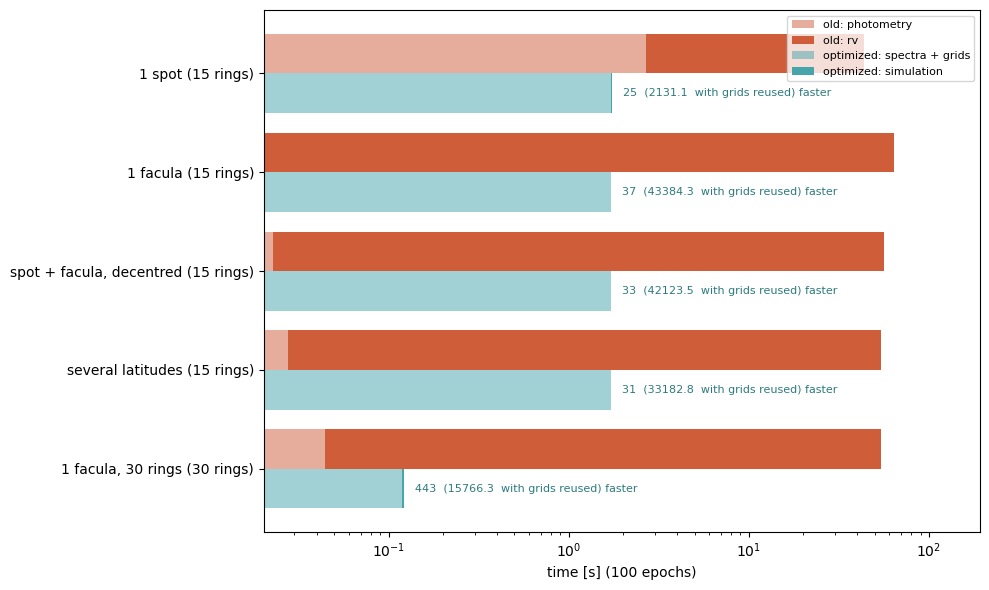

In [11]:
fig, ax = plt.subplots(figsize=(10, 0.9 * len(cases) + 1.5))
y = np.arange(len(cases))
ax.barh(y - 0.2, table['old: photometry'], 0.4, color='#cf5d3a', alpha=0.5, label='old: photometry')
ax.barh(y - 0.2, table['old: rv'], 0.4, left=table['old: photometry'], color='#cf5d3a', label='old: rv')
ax.barh(y + 0.2, table['opt: spectra + grids'], 0.4, color='#45a5aa', alpha=0.5, label='optimized: spectra + grids')
ax.barh(y + 0.2, table['opt: simulation'], 0.4, left=table['opt: spectra + grids'], color='#45a5aa', label='optimized: simulation')
ax.set_yticks(y)
ax.set_yticklabels(['%s (%d rings)' % (c, cases[c][0]) for c in cases])
ax.invert_yaxis()
ax.set_xscale('log')
gain = (table['old: total'] / table['opt: total'])            # time saved by the optimized version [%]
gain_reused = (table['old: total'] / table['opt: simulation'])  # same, grids already built
for yi, c in zip(y, cases):
    ax.text(table.loc[c, 'opt: total'] * 1.15, yi + 0.2, '%.0f  (%.1f  with grids reused) faster' % (gain[c], gain_reused[c]),
            va='center', fontsize=8, color='#2c7a7e')
ax.set_xlim(right=table['old: total'].max() * 3)
ax.set_xlabel('time [s] (%d epochs)' % n_epochs)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Comparison of the outputs

For `comparison_case`: filling factors of the spots and faculae, light curve (normalised to the quiet star), and RV, FWHM, BIS and contrast of the CCFs. RV, FWHM and BIS are shown relative to their median (the two versions use different reference points), the contrast relative to its median. Both versions extrapolate the intensity below the smallest μ the same way (linear, section 2). Small differences are expected: the facula under a spot is computed differently in the two versions (partial overlap, several spots), and the CCF fits differ (scipy vs Numba). Section 8 shows where these differences come from.


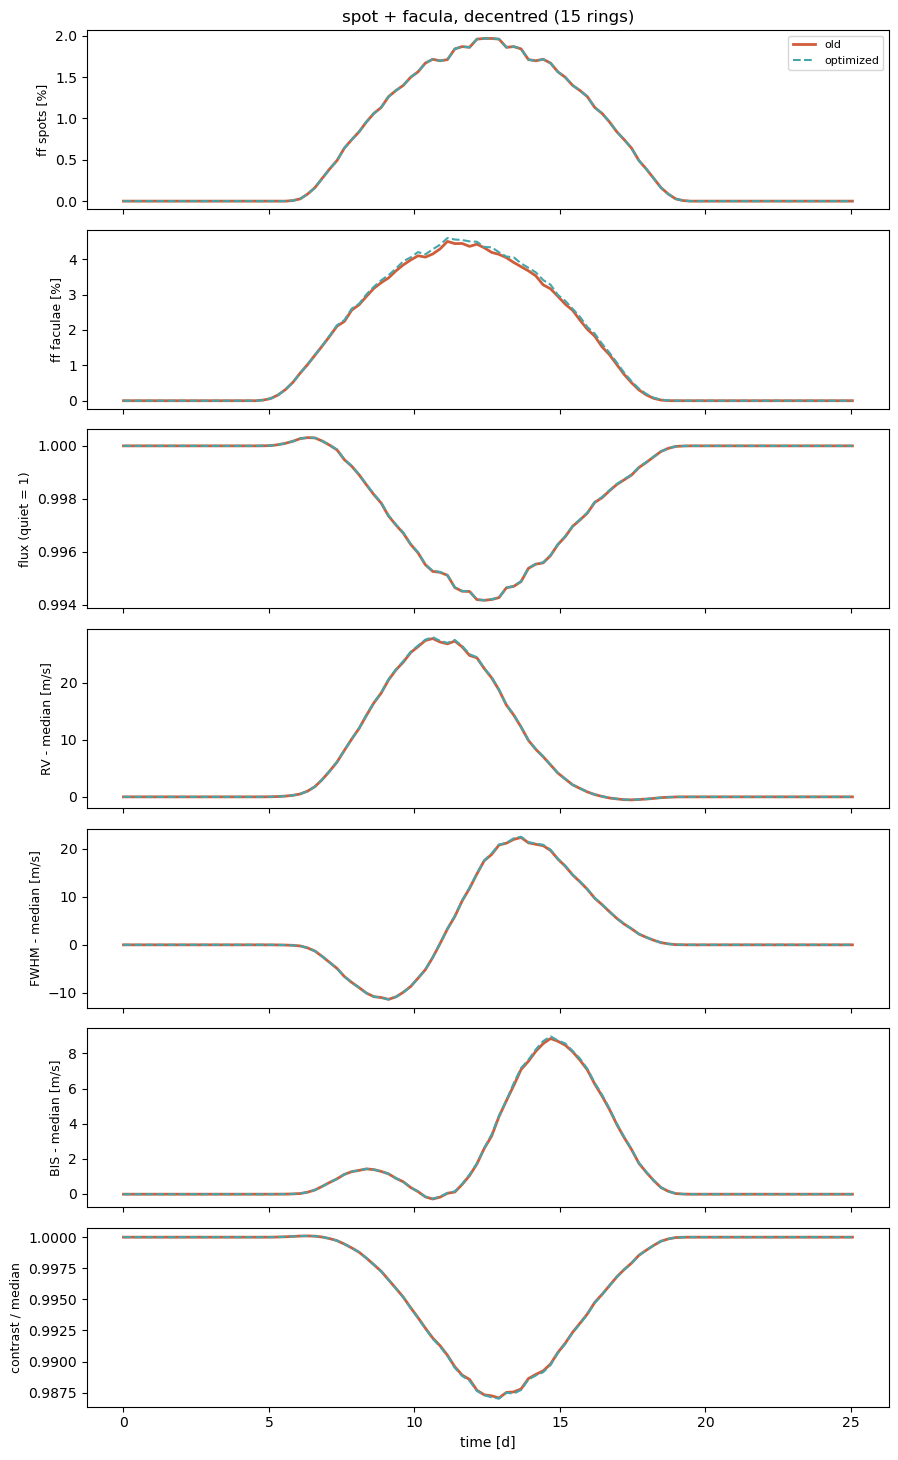

,max |old - optimized|,"signal (old, max - min)"
quantity,,
ff spots [%],1.354e-14,1.966
ff faculae [%],0.1446,4.505
flux (quiet = 1),2.843e-05,0.006144
RV - median [m/s],0.2379,28.31
FWHM - median [m/s],0.2357,33.74
BIS - median [m/s],0.1424,9.135
contrast / median,0.0001287,0.01303


In [12]:
def compare_outputs(case):
    """Plot the outputs of the old and optimized versions for one case and return the table of their differences."""
    old, new = old_runs[case], new_runs[case]
    quiet_total = grids[cases[case][0]]['quiet_total']
    rows = [('ff spots [%]', old.results['ff_sp'], new.ff_sp, 'abs'),
            ('ff faculae [%]', old.results['ff_fc'], new.ff_fc, 'abs'),
            ('flux (quiet = 1)', old.results['lc'], new.flux_var / quiet_total, 'abs'),
            ('RV - median [m/s]', old.results['rv'], new.rv_var, 'median'),
            ('FWHM - median [m/s]', old.results['fwhm'], new.fwhm_var, 'median'),
            ('BIS - median [m/s]', old.results['bis'], new.bis_var, 'median'),
            ('contrast / median', old.results['contrast'], new.contrast_var, 'ratio')]

    fig, axes = plt.subplots(len(rows), 1, figsize=(9, 2.1 * len(rows)), sharex=True)
    diffs = []
    for ax, (name, a, b, how) in zip(axes, rows):
        a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
        if how == 'median':
            a, b = a - np.median(a), b - np.median(b)
        elif how == 'ratio':
            a, b = a / np.median(a), b / np.median(b)
        ax.plot(times, a, '-', lw=2, color='#cf5d3a', label='old')
        ax.plot(times, b, '--', lw=1.5, color='#45a5aa', label='optimized')
        ax.set_ylabel(name, fontsize=9)
        diffs.append({'quantity': name, 'max |old - optimized|': np.max(np.abs(a - b)), 'signal (old, max - min)': np.ptp(a)})
    axes[0].legend(fontsize=8)
    axes[0].set_title('%s (%d rings)' % (case, cases[case][0]))
    axes[-1].set_xlabel('time [d]')
    plt.tight_layout()
    plt.show()

    pd.options.display.float_format = '{:.4g}'.format
    return pd.DataFrame(diffs).set_index('quantity')

compare_outputs(comparison_case)

**Faculae alone, 30 rings.** The same comparison for `1 facula, 30 rings`: one facula without a spot, on the finer grid.

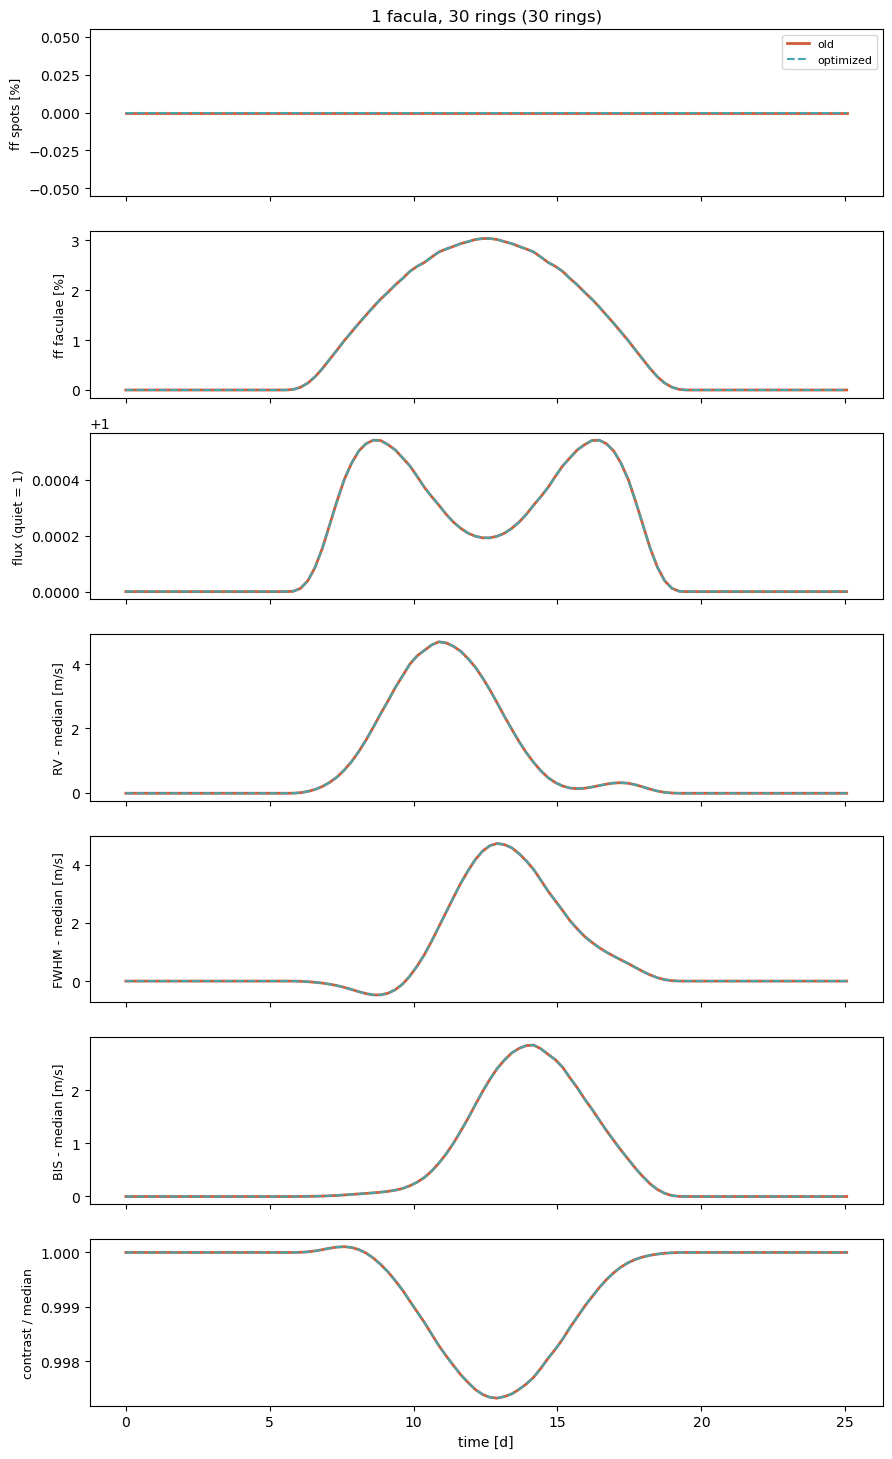

,max |old - optimized|,"signal (old, max - min)"
quantity,,
ff spots [%],0,0
ff faculae [%],3.997e-15,3.034
flux (quiet = 1),7.695e-10,0.0005405
RV - median [m/s],7.266e-05,4.723
FWHM - median [m/s],4.484e-05,5.197
BIS - median [m/s],1.095e-05,2.852
contrast / median,1.123e-07,0.002782


In [13]:
compare_outputs('1 facula, 30 rings')

## 8. Where the CCF differences come from

**Limb, μ < 0.1.** The MURaM spectra are tabulated at μ = 0.1, 0.2, …, 1.0, but the outer rings of the grid are closer to the limb (μ = 0.054 with 15 rings, μ = 0.080 and 0.027 with 30 rings). Both versions extrapolate there as I(μ) = μ / 0.1 · I(0.1) (`limb_extrapolation = linear` in section 2). With the template's `constant` (I(μ) = I(0.1)) the limb rings of the quiet star and of the regions are brighter in the old version; since every ring weights the CCF, this shifts the RV at every epoch, not only at the ingress and egress (~0.01 m/s for `1 facula, 30 rings`).

**Why the facular filling factor differs.** The spot filling factors always agree to 1e-14. The facular ones differ only when spots and faculae are present together, and only at the epochs when a spot is in front of a facula. The cause is how each version computes the visible part of a facula in a cell that a spot also covers (the spot is on top of the facula).

In every cell, let d_fc be the fraction of the cell inside a facula disc and d_sp the fraction inside a spot disc (the same `overlap_fraction` ramp in both versions). With 15 rings a cell is 6.2° wide, comparable to the regions, so many cells are only partly covered.

*Old version* (`loop_generate_rotating_*_nb` of the `starsim` package). For each facula it computes `dfc -= dsp`, where `dsp` is the variable left over from the spot loop. The regions are sorted with the spots first, so `dsp` is the fraction of the **last spot in the list** in that cell, not the fraction of the spot that sits on this facula. At the end it clips `afc + asp ≤ 1`.

*Optimized version* (`generate_ff_core`). Once per epoch it checks how every spot–facula pair of discs is placed, then in every cell:

| how the discs are placed | visible facula in the cell |
|---|---|
| spot entirely inside the facula | d_fc − d_sp (sum over these spots) |
| facula entirely inside the spot | 0 |
| no overlap | d_fc |
| partial overlap | d_fc · (1 − d_sp) (spot and facula assumed independent inside the cell) |

This gives two effects:

1. **Partial overlap: old < optimized** (`spot + facula, decentred`). The spot (8°) is centred 10° from the facula centre (14°), and 10° + 8° > 14°, so the spot sticks out of the facula. There is only one spot, so the old code subtracts the correct spot, but all of it: d_fc − d_sp. The optimized code removes only d_fc · d_sp. The difference in one cell is optimized − old = d_sp · (1 − d_fc) ≥ 0. It is non-zero only in the cells on the edge of the facula that the spot crosses, and reaches ~0.14 % of the disc (out of a 4.5 % signal). Neither rule is exact here (the exact answer needs the area shared by the two discs inside the cell). The old rule underestimates the facula, because part of the spot in such a cell lies outside the facula.
2. **Several spots: old > optimized** (`several latitudes`). In a cell of the first or second pair, the old code subtracts the fraction of the third spot, which is 0 there. So the facula under its own spot is not removed, except by the final clip `afc + asp ≤ 1`, which only acts where d_fc + d_sp > 1. In the cells at the edge of the spot where the facula does not fully cover the cell (d_fc < 1, d_fc + d_sp ≤ 1), the old code counts facula under the spot. This is a bookkeeping error of the old code: it depends on the order of the spots in the list. The optimized result does not depend on that order.

*Checks* (run outside the notebook; `sunsim/nbspectra.py` is unchanged):
* with the partial-overlap rule of `generate_ff_core` replaced by the old one (facula − spot), the decentred case agrees to 0 at all 100 epochs;
* one concentric pair (spot 7°, facula 12°) agrees to 0; two concentric pairs already differ (old larger, up to 0.08 %). This is what the stale `dsp` predicts.

The cell after the plot gives old − optimized of the facular filling factor for every case.

The extra (or missing) facular area also changes RV, FWHM and BIS at the same epochs.

**The plot.** For the two cases of section 7, at every epoch: RV, FWHM and BIS old − optimized (median removed, as in section 7) and facular filling factor old − optimized. With the facula alone the two versions agree to ~1e-4 m/s. In the decentred case the differences follow the facular filling factor, which is negative (old < optimized) while the spot is in front of the facula edge.


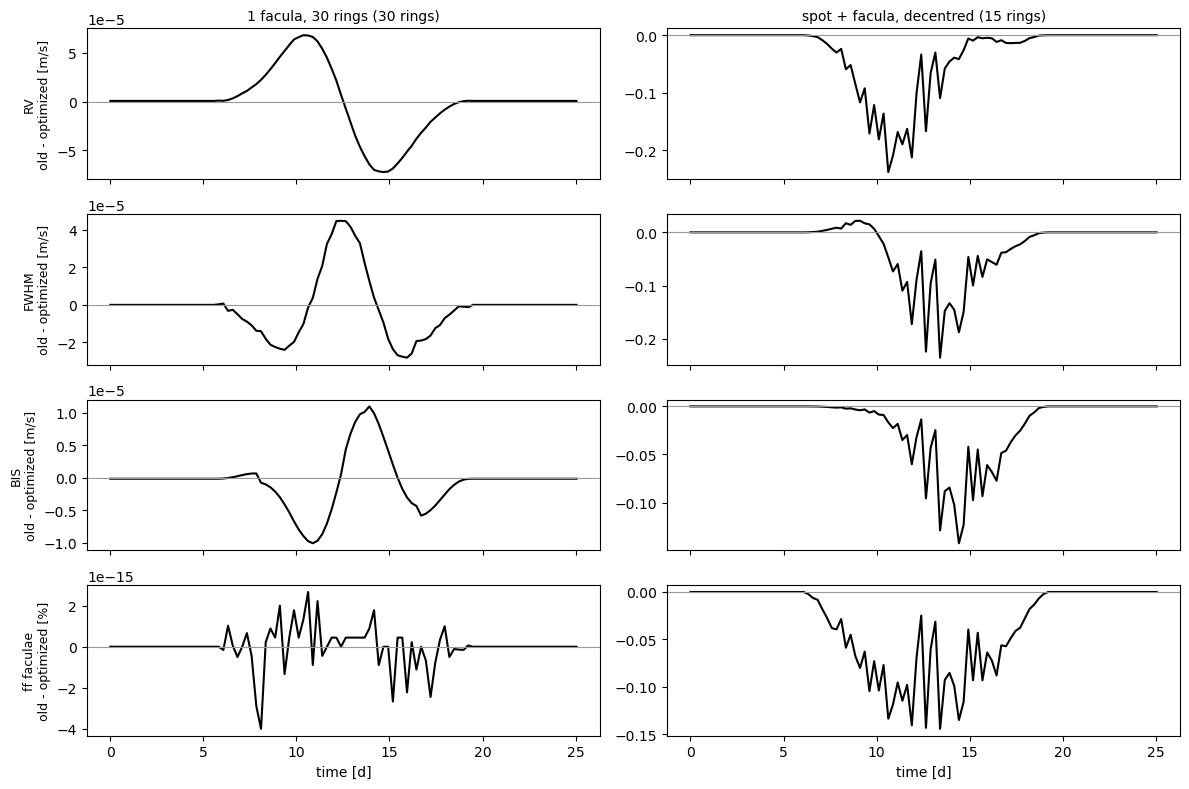

,max |d RV| [m/s],max |d FWHM| [m/s],max |d BIS| [m/s],max |d ff faculae| [%]
case,,,,
"1 facula, 30 rings",7.27e-05,4.48e-05,1.09e-05,4e-15
"spot + facula, decentred",0.238,0.236,0.142,0.145


In [14]:
limb_cases = ['1 facula, 30 rings', comparison_case]
rows = [('RV', 'rv', 'rv_var', '[m/s]'), ('FWHM', 'fwhm', 'fwhm_var', '[m/s]'), ('BIS', 'bis', 'bis_var', '[m/s]'),
        ('ff faculae', 'ff_fc', 'ff_fc', '[%]')]
fig, axes = plt.subplots(len(rows), len(limb_cases), figsize=(6 * len(limb_cases), 8), sharex=True, squeeze=False)
summary = []
for j, case in enumerate(limb_cases):
    old, new = old_runs[case], new_runs[case]
    s = {'case': case}
    for ax, (name, k_old, k_new, unit) in zip(axes[:, j], rows):
        a, b = np.asarray(old.results[k_old], dtype=float), np.asarray(getattr(new, k_new), dtype=float)
        if k_old != 'ff_fc':
            a, b = a - np.median(a), b - np.median(b)
        ax.plot(times, a - b, color='k')
        ax.axhline(0, color='0.6', lw=0.8)
        s['max |d %s| %s' % (name, unit)] = np.max(np.abs(a - b))
    summary.append(s)
    axes[0, j].set_title('%s (%d rings)' % (case, cases[case][0]), fontsize=10)
    axes[-1, j].set_xlabel('time [d]')
for ax, (name, _, _, unit) in zip(axes[:, 0], rows):
    ax.set_ylabel('%s\nold - optimized %s' % (name, unit), fontsize=9)
plt.tight_layout()
plt.show()

pd.options.display.float_format = '{:.3g}'.format
pd.DataFrame(summary).set_index('case')


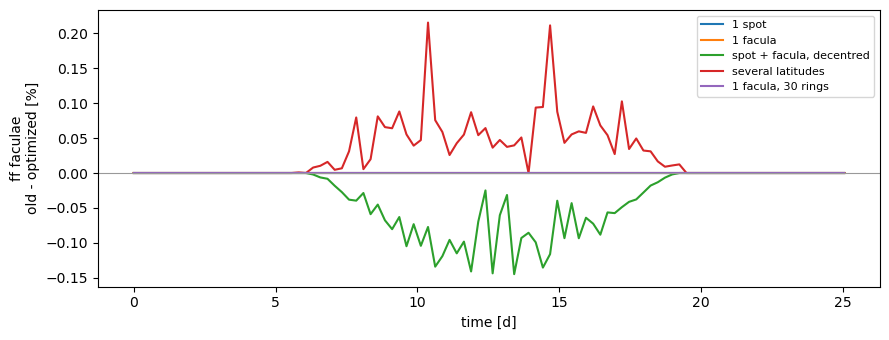

,min old - opt [%],max old - opt [%],"ff faculae (old, max) [%]"
case,,,
1 spot,0,0,0
1 facula,-9.33e-15,7.11e-15,3.08
"spot + facula, decentred",-0.145,5e-16,4.51
several latitudes,-8.33e-16,0.215,7.65
"1 facula, 30 rings",-4e-15,2.66e-15,3.03


In [15]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ff_summary = []
for case in cases:
    d = np.asarray(old_runs[case].results['ff_fc'], dtype=float) - np.asarray(new_runs[case].ff_fc, dtype=float)
    ax.plot(times, d, label=case)
    ff_summary.append({'case': case, 'min old - opt [%]': d.min(), 'max old - opt [%]': d.max(),
                       'ff faculae (old, max) [%]': np.max(old_runs[case].results['ff_fc'])})
ax.axhline(0, color='0.6', lw=0.8)
ax.set_xlabel('time [d]')
ax.set_ylabel('ff faculae\nold - optimized [%]')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.options.display.float_format = '{:.3g}'.format
pd.DataFrame(ff_summary).set_index('case')

## 9. Old configuration files: `old_config.simulate_old_config`

`sunsim/old_config.py` (`sunsim.simulate_old_config`) runs SunSim from a `.conf` file of the old version, for users who do not want to learn the new interface:

```python
from old_config import simulate_old_config
res = simulate_old_config('my_old.conf', times=t, observables=['lc', 'rv', 'fwhm', 'bis', 'contrast'])
res['lc'], res['rv'], res['fwhm'], res['bis'], res['contrast'], res['ff_sp'], res['CCF'], ...   # keys of the old results
```

It reads the old file (missing option keys get a default, unused keys are ignored, paths of other computers are looked for in the old package; all listed in a report), builds the spectra and the grids as the old code for its spectral library (Phoenix: limb brightening of the faculae, CIFIST / Dumusque bisectors; MURaM: its own bisectors, spot = black body ratio, `remove_bis_spot`, `add_median_diff`; MURaM high resolution: CCF of every ring), and runs the new `StarSim` with the circular regions of the spot map or the 2D maps (`sdo_input = 1`).

By default it does not reproduce a few bugs of the old code (module docstring of `sunsim/old_config.py`); `reproduce_old_bugs=True` reproduces them too, so that the outputs are those of the old code. One difference remains in both cases, because it is in the simulation itself (`generate_ff_core`): the visible part of the faculae when spots and faculae overlap. The old code subtracted from every facula the fraction of the **last visible spot** of its list, whatever spot covers the facula; SunSim subtracts the spots that cover it. The two agree for one spot inside its facula, and differ when a facula is covered in part by a spot, by several spots, or when another spot is visible elsewhere.

Below: the cases of this notebook, computed with `simulate_old_config` from the configuration files of section 2, against the old code of section 4. `1 spot`, `1 facula` and `1 facula, 30 rings` are the same to the rounding and the precision of the CCF fits; `spot + facula, decentred` (partial overlap) and `several latitudes` (three spots visible at the same time) show the overlap rule, in the faculae only (`ff_sp` is the same).

In [16]:
from sunsim import simulate_old_config

rows_conv = []
converted = {}
for name, (n_rings, regions) in cases.items():
    path, _ = old_conf(n_rings)
    res = simulate_old_config(path, times=times, observables=['lc', 'rv', 'fwhm', 'bis', 'contrast'],
                              spot_map=old_spot_map(regions), old_package=old_package, reproduce_old_bugs=True,
                              verbose=False)
    converted[name] = res
    old = old_runs[name].results
    row = {'case': name}
    for key, label in (('ff_sp', 'ff spots [%]'), ('ff_fc', 'ff faculae [%]'), ('lc', 'flux'), ('rv', 'RV [m/s]'),
                       ('fwhm', 'FWHM [m/s]'), ('bis', 'BIS [m/s]'), ('contrast', 'contrast')):
        row[label] = np.max(np.abs(np.asarray(old[key], dtype=float) - np.asarray(res[key], dtype=float)))
    rows_conv.append(row)
pd.options.display.float_format = '{:.2g}'.format
print('max |old code - simulate_old_config| for every output:')
pd.DataFrame(rows_conv).set_index('case')

max |old code - simulate_old_config| for every output:


,ff spots [%],ff faculae [%],flux,RV [m/s],FWHM [m/s],BIS [m/s],contrast
case,,,,,,,
1 spot,9.3e-15,0,8.9e-16,9.4e-07,2.2e-05,1.3e-12,4e-10
1 facula,0,9.3e-15,1.1e-15,7.5e-07,2e-05,9.1e-13,2.5e-10
"spot + facula, decentred",1.4e-14,0.14,2.8e-05,0.24,0.24,0.14,0.00013
several latitudes,1.1e-14,0.22,3.7e-05,0.36,0.29,0.22,0.00016
"1 facula, 30 rings",0,4e-15,2.4e-15,6.3e-07,2.3e-05,2.3e-12,4.8e-10


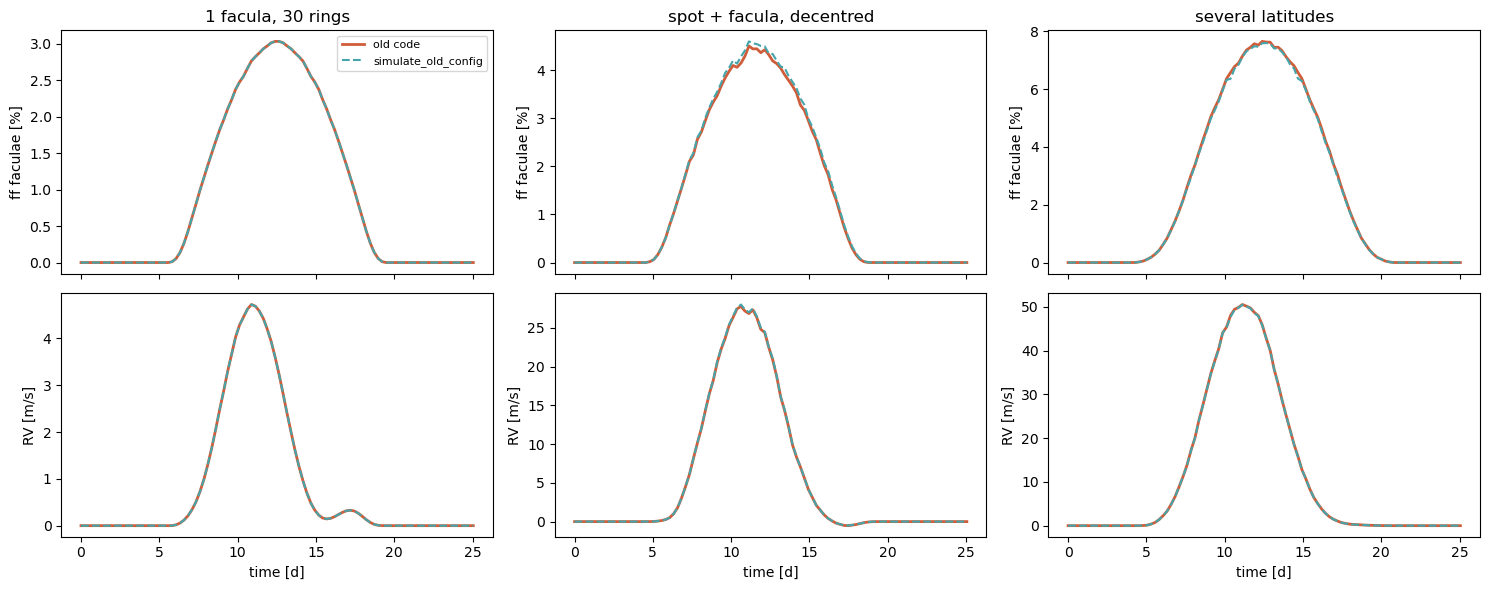

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
for j, name in enumerate(['1 facula, 30 rings', 'spot + facula, decentred', 'several latitudes']):
    old, res = old_runs[name].results, converted[name]
    for i, (key, label) in enumerate((('ff_fc', 'ff faculae [%]'), ('rv', 'RV [m/s]'))):
        ax = axes[i, j]
        ax.plot(times, old[key], '-', lw=2, color='#cf5d3a', label='old code')
        ax.plot(times, res[key], '--', lw=1.5, color='#45a5aa', label='simulate_old_config')
        ax.set_ylabel(label)
    axes[0, j].set_title(name)
    axes[1, j].set_xlabel('time [d]')
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Automatic tests against the old version

`tests/old_version/test_old_version.py` compares SunSim (through `simulate_old_config`, with `reproduce_old_bugs=True`) with the old code on ~50 cases, to run after every change of SunSim:

```
python tests/old_version/test_old_version.py              # all the cases (environment sunsim)
python tests/old_version/test_old_version.py -k phx         # the cases whose name contains 'phx'
python tests/old_version/test_old_version.py --list         # the cases
python tests/old_version/test_old_version.py --refresh      # run the old code again
```

* **Cases.** Phoenix (inclination 60° and 120°, pole-on, fast rotator, large star, differential rotation, reference time, many regions, 8 and 30 rings, lifetimes and evolution laws, temperatures between the models, logg 4.4, convective shift ±, `ccf_norm` 0, `flux_flat` 0, weighted mask lines, other velocity grid, missing filter, limb extrapolation and `limb_lim`, limb darkening laws, Meunier limb brightening, `mps_mu_grid`, transiting planets, circular and eccentric), MURaM low and high resolution (bisector options, inclination with differential rotation), the **HARPS-N instrument** (CCFs order by order: resolution, 72 orders, blaze × efficiency), **2D maps**: the synthetic maps of the old package, synthetic maps with faculae, and **real SDO maps** of spots and faculae (12 epochs of 944 × 944 maps from the Google Drive folder, linked, not copied; MURaM, Phoenix, 30 rings, MURaM high resolution, and with HARPS-N). The cases with the real SDO maps are skipped (`SKIP`) on a computer without them (`SDO_REAL_MAPS` sets their folder).
* **Old results.** The old code runs once per case in its environment (`env_sunsim`, a new process, caches in `tests/old_version/reference/`: the old package is not modified) and its results are kept, with a hash of the configuration, the regions, the epochs and the old source code: it runs again only when one of them changes. First run ~25 min, then ~1 min.
* **Tolerances.** Light curve, filling factors and BIS: the same numbers (rounding, 1e-9). RV, FWHM, contrast: they come from a gaussian fit (scipy in the old code, Numba in SunSim), within 0.01 m/s, 0.05 m/s and 1e-6 (~1e-4 of the signals).
* **Known differences.** Changes made on purpose are cases marked `KNOWN`: the overlap rule of section 9 (`overlap_*`), and the old bugs that `simulate_old_config` does not reproduce by default (`fixed_*`: Phoenix angles, constant limb extrapolation with Phoenix, projection and faculae of the 2D maps, coverage of the cells by the planets, HARPS-N efficiency). Their tolerance is a bound a bit above the difference measured when the change was made, so that a regression is still detected. When a change of SunSim changes the results on purpose, update the tolerance of the cases concerned and write why in `KNOWN`.

Below: all the cases (from the stored old results; the old code only runs for the cases that have none), then examples of cases that pass, and all the cases with a known difference.

**HARPS-N.** With numpy 1.x (the old environment) the old code evaluated its efficiency polynomial in float32 and got a meaningless efficiency (from −1800 to +800 instead of 14–90 %, negative on a third of the pixels, which changes the weights of the pixels inside the orders; RV off by 24 m/s, FWHM by 1 km/s, BIS NaN), and so sensitive to the rounding that they cannot be reproduced; with numpy ≥ 2 the same line gives the right values. `hr_harpsn` and `sdo_real_harpsn` therefore run the old code with the efficiency in float64 (a patch at run time in `run_old_starsim.py`, the old files are not modified), and `fixed_harpsn` shows the size of the old bug.

In [18]:
sys.path.insert(0, os.path.join(REPO, 'tests', 'old_version'))
import test_old_version as tov

test_results = tov.run_cases(jobs=4, verbose=False)
def worst(r):
    """Quantity with the largest |old - new| / tolerance (finite ratios only: inf / inf = a NaN in both codes)."""
    ratios = {k: d / tol for k, (d, tol, _) in r['diffs'].items() if np.isfinite(d / tol)}
    return max(ratios, key=ratios.get) if ratios else None

table = pd.DataFrame([{'case': r['case']['name'], 'what': r['case']['what'], 'status': r['status'],
                       'largest |old - new| / tolerance': r['diffs'][worst(r)][0] / r['diffs'][worst(r)][1] if worst(r) else np.nan,
                       'quantity': worst(r) or '',
                       'known difference': ', '.join(r['case']['known'])} for r in test_results]).set_index('case')
counts = table['status'].value_counts()
print('%d cases: %s' % (len(table), ', '.join('%d %s' % (n, s) for s, n in counts.items())))
pd.options.display.float_format = '{:.2g}'.format
pd.set_option('display.max_colwidth', 90)
table

60 cases: 50 PASS, 10 KNOWN


,what,status,largest |old - new| / tolerance,quantity,known difference
case,,,,,
phx_ref,"Phoenix, spot + concentric facula on the equator, 15 rings",PASS,0.26,fwhm,
phx_spot_only,one spot alone,PASS,0.65,rv,
phx_facula_only,one facula alone,PASS,0.021,rv,
phx_incl_60,"inclination 60 deg, regions at colatitude 60",PASS,0.062,rv,
phx_incl_120,"inclination 120 deg (south pole visible), regions at colatitude 130",PASS,0.091,rv,
phx_pole_on,"pole-on star (inclination 0, vsini = 0), circumpolar regions",PASS,0.12,rv,
phx_fast_rotator,"rotation period 8 d (vsini 6 km/s), two rotations",PASS,0.079,contrast,
phx_big_star,"radius 1.6 Rsun, period 30 d",PASS,0.03,rv,
phx_diffrot,"solar differential rotation (B = -2.66), regions at 3 latitudes, two rotations (one sp...",PASS,0.21,fwhm,


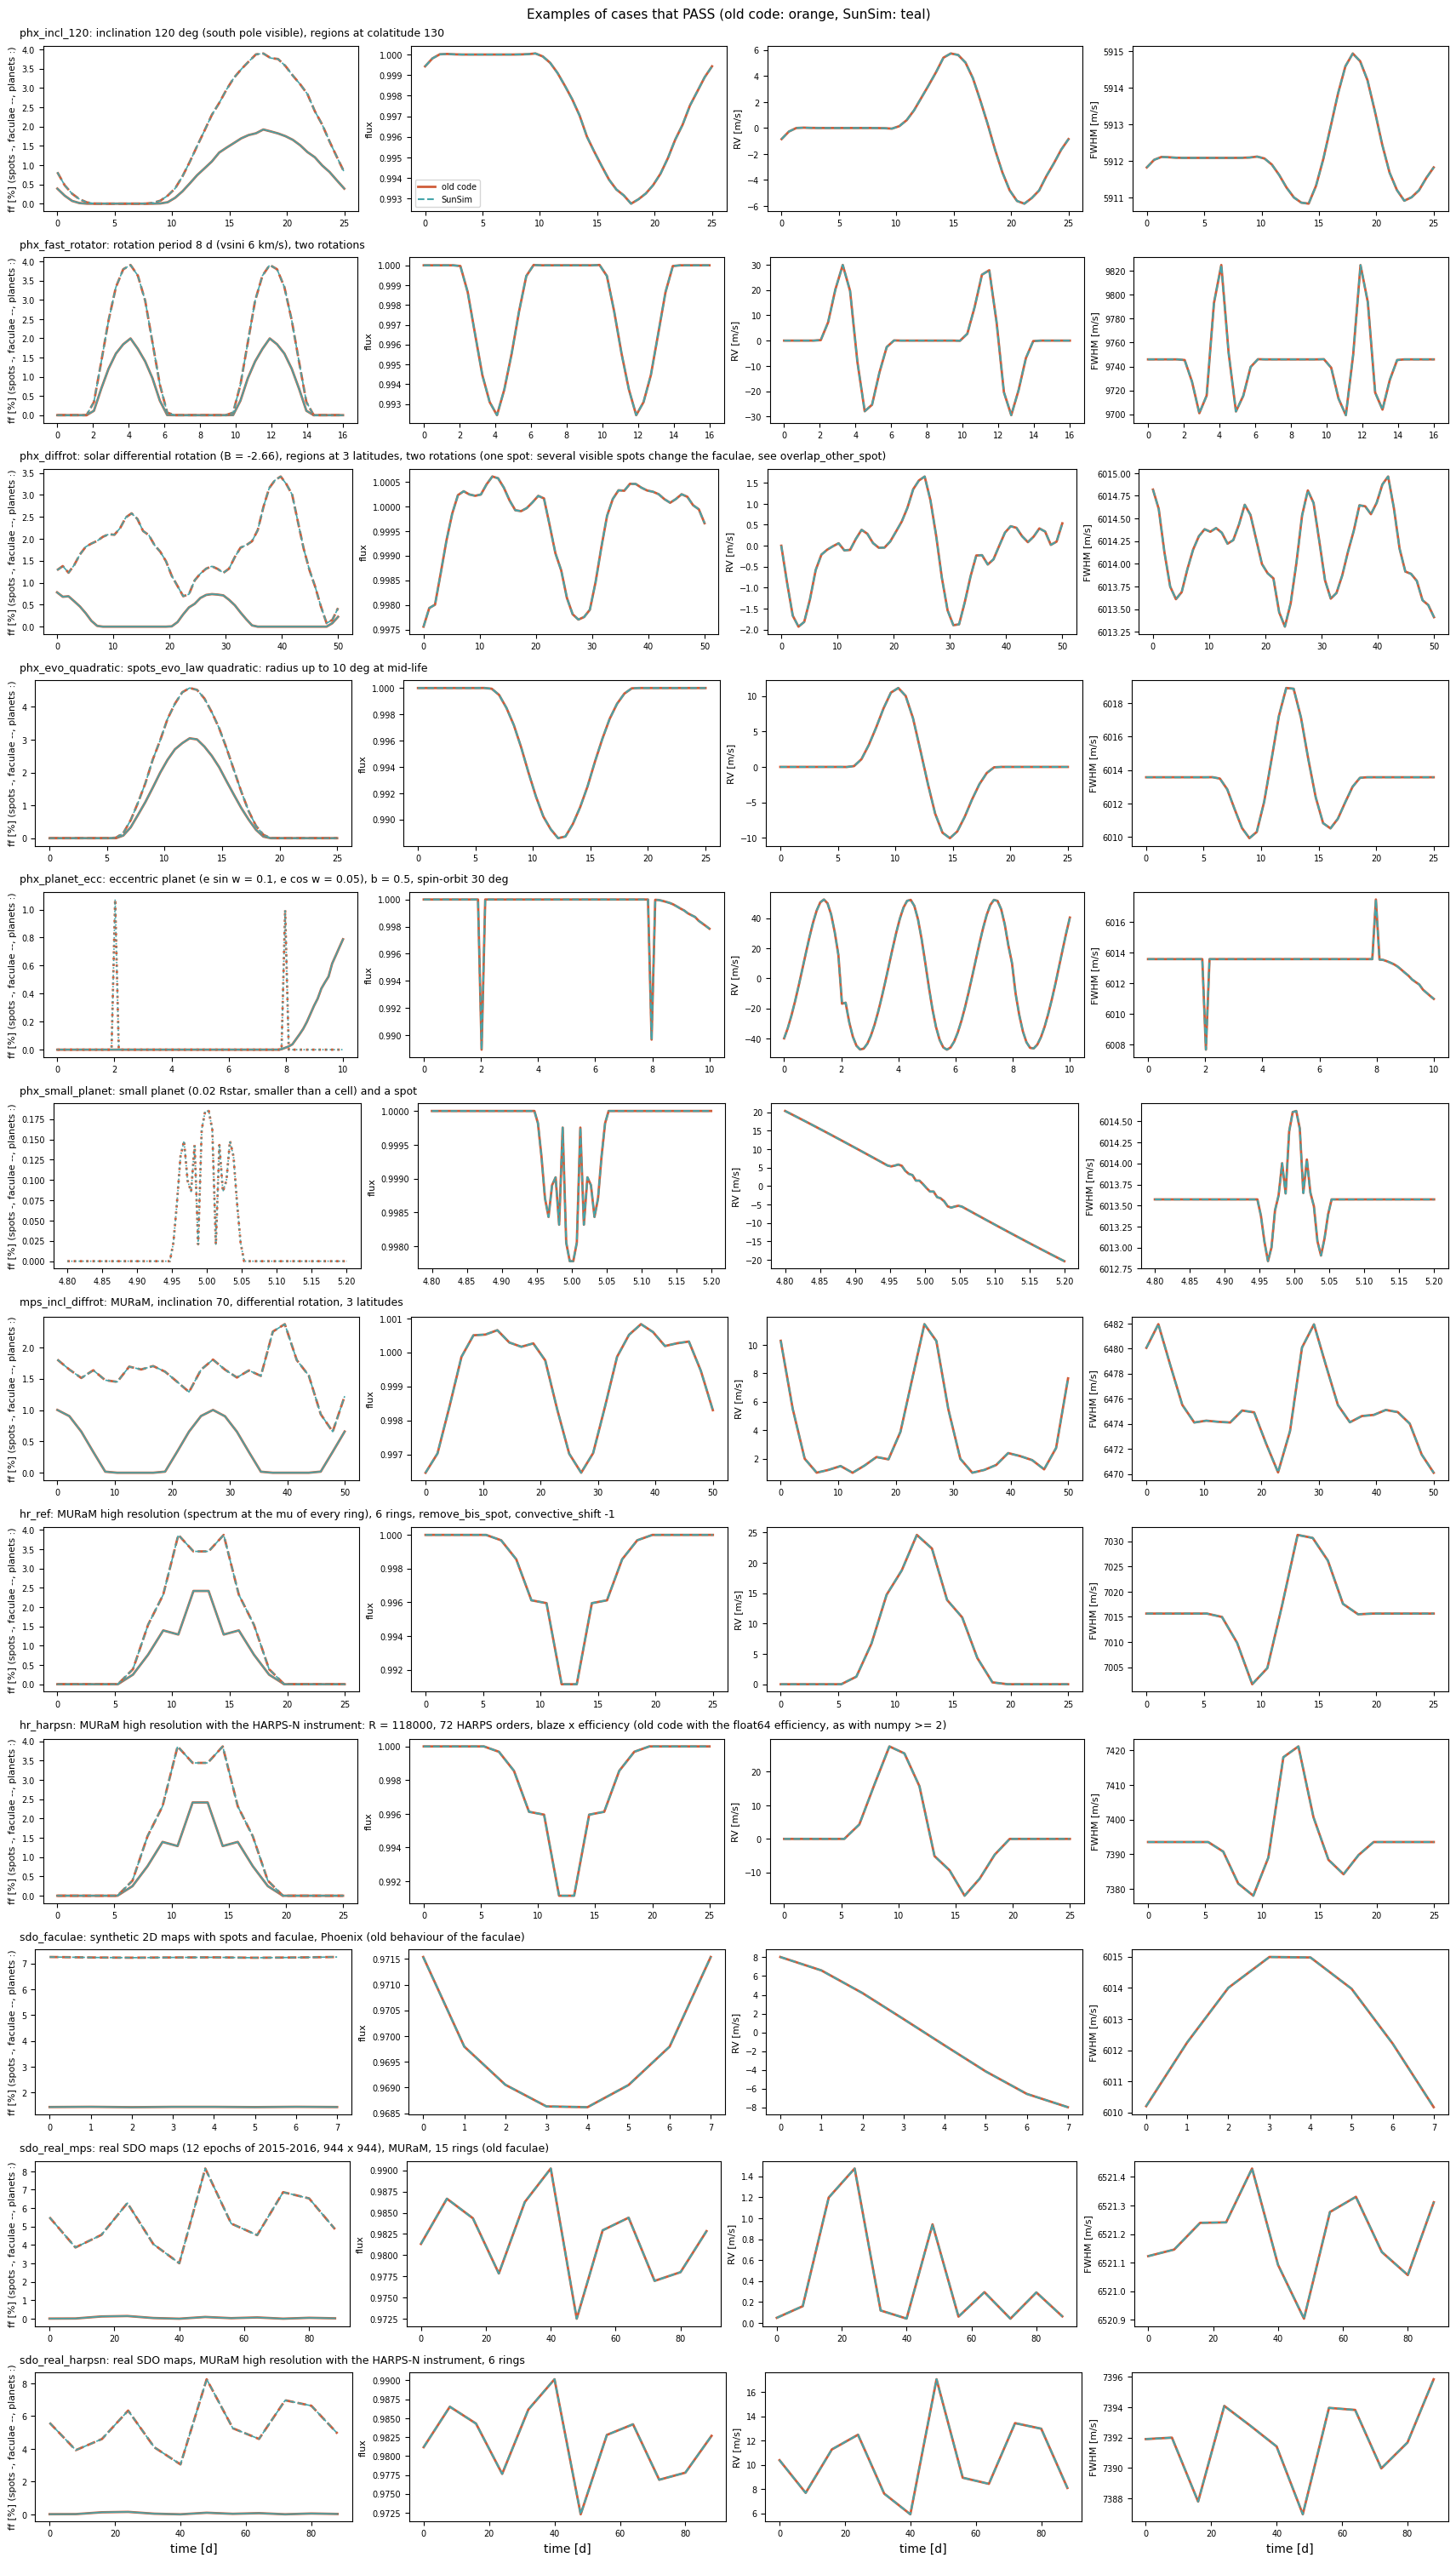

In [19]:
by_name = {r['case']['name']: r for r in test_results}
OLD, NEW = '#cf5d3a', '#45a5aa'

def compare_case(axes_row, r, panels):
    """Old code (full line) and SunSim (dashed) of one test case, one panel per (key, label); key 'ff' = spots and
    faculae and planets, ('diff', key) = old - new of that quantity."""
    t = r['old']['time']
    for ax, (key, label) in zip(axes_row, panels):
        if key == 'ff':
            for k, ls in (('ff_sp', '-'), ('ff_fc', '--'), ('ff_pl', ':')):
                if k in r['old'] and np.any(r['old'][k]):
                    ax.plot(t, r['old'][k], ls, lw=2, color=OLD)
                    ax.plot(t, r['new'][k], ls, lw=1.2, color=NEW)
        elif isinstance(key, tuple):
            k = key[1]
            ax.plot(t, r['old'][k] - r['new'][k], '-', lw=1.2, color='k')
            ax.axhline(0, color='grey', lw=0.6)
            tol = r['diffs'][k][1]
            ax.axhspan(-tol, tol, color='grey', alpha=0.15, lw=0)
        elif key in r['old']:
            ax.plot(t, r['old'][key], '-', lw=2, color=OLD, label='old code')
            ax.plot(t, r['new'][key], '--', lw=1.5, color=NEW, label='SunSim')
        else:
            ax.text(0.5, 0.5, 'not computed', ha='center', va='center', transform=ax.transAxes, color='grey', fontsize=8)
        ax.set_ylabel(label, fontsize=8)
        ax.tick_params(labelsize=7)


def case_rows(cases, panels_of, title_of, suptitle):
    """One row per case (a subfigure, so that the long titles do not squeeze the panels)."""
    fig = plt.figure(figsize=(17, 2.5 * len(cases)), layout='constrained')
    for sub, r in zip(fig.subfigures(len(cases), 1), cases):
        panels = panels_of(r)
        axes = sub.subplots(1, len(panels))
        compare_case(axes, r, panels)
        sub.suptitle(title_of(r), x=0.01, ha='left', fontsize=9)
        if r is cases[0]:
            axes[1].legend(fontsize=7)
        if r is cases[-1]:
            for ax in axes:
                ax.set_xlabel('time [d]')
    fig.suptitle(suptitle, fontsize=11)
    plt.show()

# examples of cases that pass (same numbers as the old code within the tolerances)
examples = ['phx_incl_120', 'phx_fast_rotator', 'phx_diffrot', 'phx_evo_quadratic', 'phx_planet_ecc', 'phx_small_planet',
            'mps_incl_diffrot', 'hr_ref', 'hr_harpsn', 'sdo_faculae', 'sdo_real_mps', 'sdo_real_harpsn']
assert all(by_name[n]['status'] == 'PASS' for n in examples)
panels = [('ff', 'ff [%] (spots -, faculae --, planets :)'), ('lc', 'flux'), ('rv', 'RV [m/s]'), ('fwhm', 'FWHM [m/s]')]
case_rows([by_name[n] for n in examples], lambda r: panels,
          lambda r: '%s: %s' % (r['case']['name'], r['case']['what']),
          'Examples of cases that PASS (old code: orange, SunSim: teal)')

**Cases with a known difference.** Every case marked `KNOWN`: the light curve and the RV of the old code and of SunSim, the quantity whose difference is the largest relative to its tolerance, and that difference (old − SunSim) against time, with the tolerance of the case in grey. The `overlap_*` cases change the faculae (the overlap rule), the `fixed_*` cases are old bugs that SunSim does not reproduce by default.

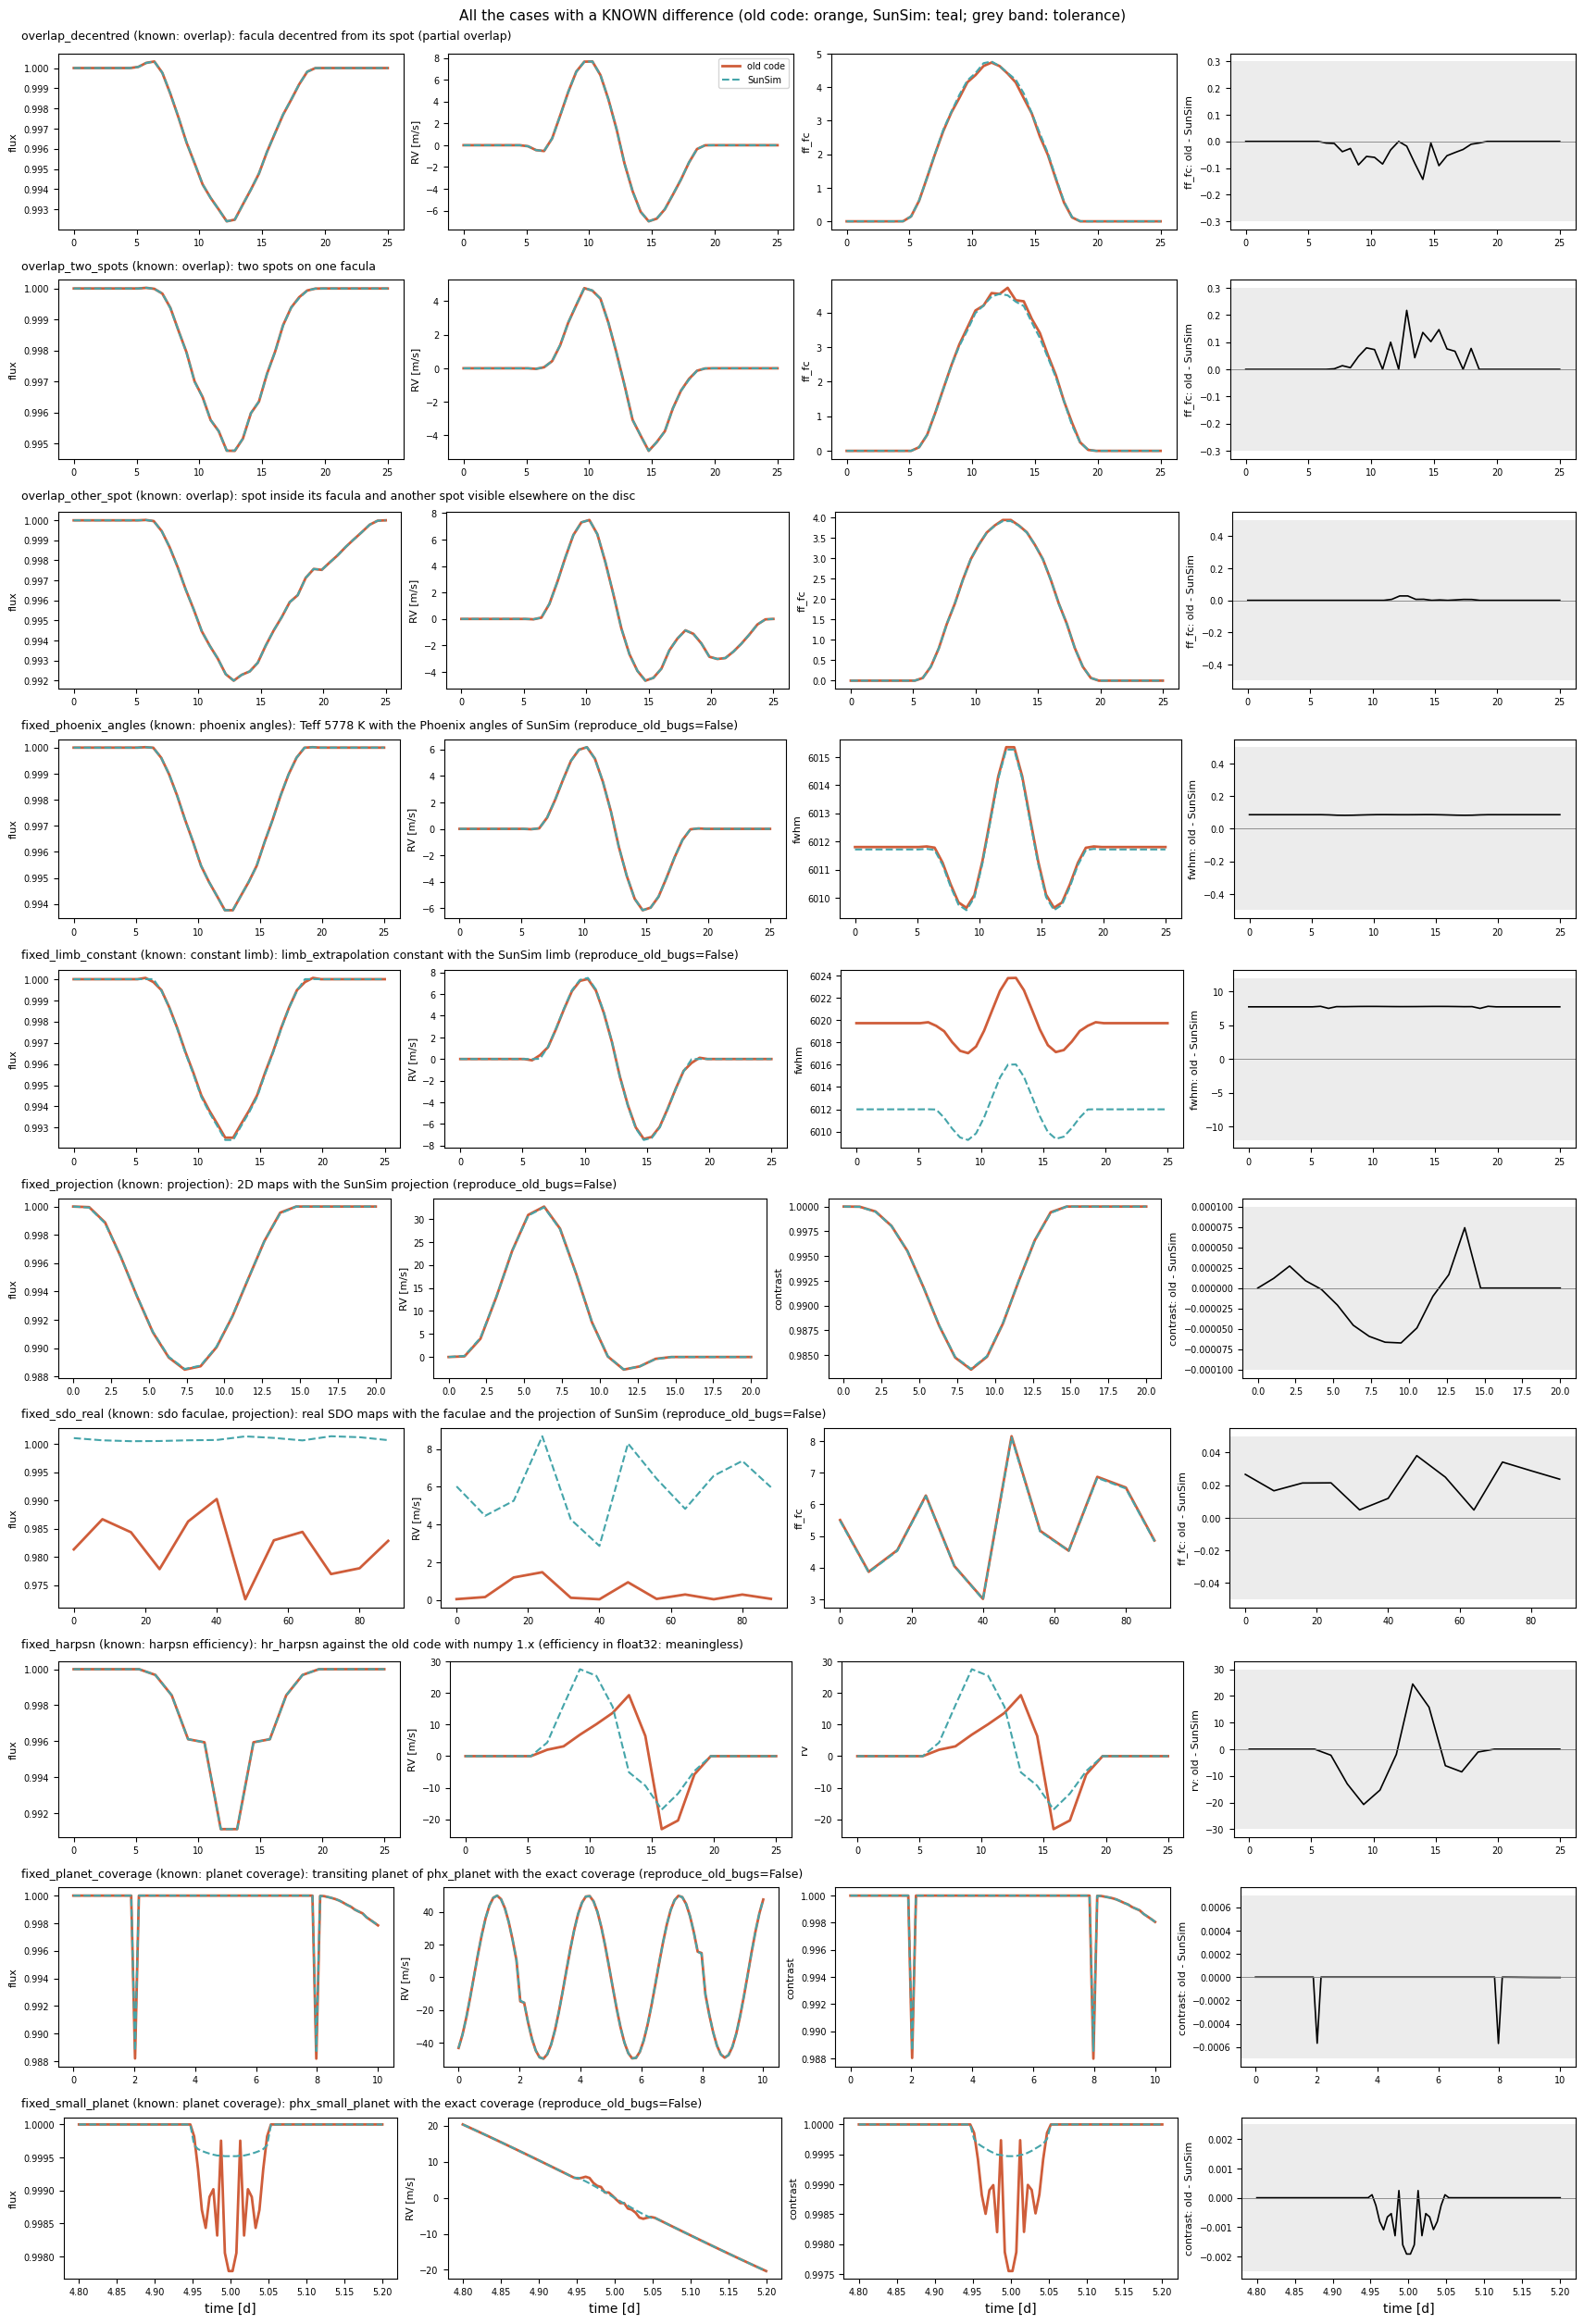

In [20]:
known = [r for r in test_results if r['status'] == 'KNOWN']

def known_panels(r):
    w = worst(r)                                        # largest difference / tolerance
    return [('lc', 'flux'), ('rv', 'RV [m/s]'), (w, w), (('diff', w), '%s: old - SunSim' % w)]

case_rows(known, known_panels,
          lambda r: '%s (known: %s): %s' % (r['case']['name'], ', '.join(r['case']['known']), r['case']['what']),
          'All the cases with a KNOWN difference (old code: orange, SunSim: teal; grey band: tolerance)')

## 11. Parameter sweeps (optimized SunSim only)

How the outputs respond to every parameter, from usual to extreme values: **one parameter changes, all the others keep the values of the base case**, and all the curves of a parameter are on the same figure. Every quantity except the filling factors is plotted **relative to its value at the first epoch** (t = 0, or the start of the transit window for the planets), so that the curves of all the values start at 0 and their variations can be compared; the filling factors are absolute (% of the disc); the levels themselves (e.g. the FWHM of the quiet star) are in `sweep_results`. Only the optimized SunSim runs here (no comparison with the old code); the spectra are the MURaM ones of section 5.

**Base case.** The Sun of the configuration of section 2 (`T_ph` = 5778 K, ΔT_spot = 400 K, P = 25.05 d, R = 1 R☉, equator-on, no differential rotation), 60 rings, one rotation in 100 epochs, **a spot of 8° with a facula of 14° around it** (the same centre, on the equator, longitude 180°), present all the time, no planet.

| parameter | values (base in bold) | extremes |
|---|---|---|
| inclination i (usual convention, 90° = equator-on) | 0, 20, 45, 70, **90**, 135, 180° | pole-on (0°, 180°): no rotational modulation |
| colatitude of the regions | 2, 30, 60, **90**, 120, 150, 178° | at the poles; north and south give the same curves equator-on |
| radius of the spot | 0, 1, 4, **8**, 12, 14, 25° | 0: facula alone; ≥ 14°: the spot hides the whole facula |
| radius of the facula | 0, 8, 10, **14**, 20, 30, 50° | ≤ 8°: hidden under the spot (spot alone) |
| spot temperature contrast ΔT | 0, 200, **400**, 800, 1500, 2500 K | 0: the spot is quiet photosphere in photometry |
| rotation period | 5, 10, **25.05**, 50, 100 d | v sin i = 10 km/s at 5 d |
| stellar radius | 0.5, **1**, 2, 5 R☉ | v sin i = 10 km/s at 5 R☉ |
| differential rotation B (regions at colatitude 45°) | 2.66, **0**, −1, −2.66 (Sun), −5, −10 deg/day | anti-solar (B > 0), and 4× the Sun |
| lifetime (appears at t = P/4) | 0.5, 2, 6, 12 d, **∞** | half a day |
| number of rings | 5, 10, 15, 30, **60**, 100, 200 | convergence of the grid |
| planet radius (transit of ~0.4 d) | **none**, 0.01, 0.03, 0.1, 0.2, 0.3 R★ | Earth-size to a hot Jupiter around an M dwarf |
| planet impact parameter | **0.3**, 0, 0.6, 0.9, 1.05, 1.2 | grazing (1.05) and no transit (1.2) |
| spin-orbit angle λ | **0**, 45, 90, 135, 180° | polar, retrograde: Rossiter–McLaughlin effect |

The planet sweeps cover only the transit (100 epochs in ±0.3 d around it), with a planet of 0.1 R★ at 20 R★ on an orbit of 25.05 d, crossing the disc when the regions of the base case are at its centre, and no Keplerian RV (`planet_semi_amplitude = 0`) so that only the Rossiter–McLaughlin effect is in the RV. For the rotation period and the stellar radius, the velocity grid is ±60 km/s (the mask lines within 3 Å of the band edges removed), so that the CCF of a fast rotator is not cut. B is the coefficient of the old configuration files, Ω(lat) = Ω_eq + B sin²(lat) + …, B = −2.66 deg/day for the Sun (Poljančić et al. 2017); it gives SunSim `differential_rotation = (1.698 B / 2.66, 2.346 B / 2.66)`, i.e. `SOLAR_DIFFERENTIAL_ROTATION` for the Sun, as `old_config`. The grids are computed once per number of rings, spot temperature and velocity grid.

In [21]:
# base case and sweeps: name -> (parameter, values, unit, base value)
base = dict(inclination=90.0, colatitude=90.0, spot_radius=8.0, facula_radius=14.0, dT_spot=400.0, period=P_rot,
            stellar_radius=1.0, B=0.0, lifetime=np.inf, n_rings=60, planet_radius=None, impact=0.3, spin_orbit=0.0)
sweeps = {
    'inclination':            ('inclination', [0, 20, 45, 70, 90, 135, 180], 'deg'),
    'colatitude':             ('colatitude', [2, 30, 60, 90, 120, 150, 178], 'deg'),
    'spot radius':            ('spot_radius', [0, 1, 4, 8, 12, 14, 25], 'deg'),
    'facula radius':          ('facula_radius', [0, 8, 10, 14, 20, 30, 50], 'deg'),
    'spot contrast':          ('dT_spot', [0, 200, 400, 800, 1500, 2500], 'K'),
    'rotation period':        ('period', [5, 10, P_rot, 50, 100], 'd'),
    'stellar radius':         ('stellar_radius', [0.5, 1, 2, 5], 'R_sun'),
    'differential rotation':  ('B', [2.66, 0, -1, -2.66, -5, -10], 'deg/d'),     # B < 0: solar-like (Sun: -2.66)
    'lifetime':               ('lifetime', [0.5, 2, 6, 12, np.inf], 'd'),
    'number of rings':        ('n_rings', [5, 10, 15, 30, 60, 100, 200], ''),
    'planet radius':          ('planet_radius', [None, 0.01, 0.03, 0.1, 0.2, 0.3], 'R_star'),
    'impact parameter':       ('impact', [0.3, 0, 0.6, 0.9, 1.05, 1.2], ''),
    'spin-orbit angle':       ('spin_orbit', [0, 45, 90, 135, 180], 'deg'),
}
planet_sweeps = {'planet radius', 'impact parameter', 'spin-orbit angle'}
wide_rv_sweeps = {'rotation period', 'stellar radius'}
a_planet = 20.0                 # [stellar radii]; planet period = P_rot: a transit of ~0.4 d

sweep_grids = {}

def sweep_grid(n_rings, dT_spot, wide_rv):
    """Photometric and CCF grids (cached) for a number of rings, a spot contrast and a velocity grid."""
    key = (n_rings, dT_spot, wide_rv)
    if key not in sweep_grids:
        T_spot = T_ph - dT_spot
        rv = np.arange(-60000, 60000 + rv_step, rv_step) if wide_rv else rv_grid
        keep = (wvm > band[0] + 3) & (wvm < band[1] - 3) if wide_rv else np.ones(len(wvm), bool)
        def phot(spectra, filt):
            g = flux_grid(n_rings, spectra, 'x', filt, *band, mode='photometry')
            g.built_grid()
            return g
        def ccf(spectrum, brightness, keep_bisector):
            g = CCF_grid(n_rings, spectrum, rv, wvm[keep], fm[keep], phoenix_resolution=True, normalization=ccf_norm,
                         mu_ratio=brightness.grid / brightness.parea / norm)
            g.built_grid(bisector=None)
            if keep_bisector:                       # as in section 5
                g.rvs_ring = np.tile(g.rvs, (n_rings, 1))
            return g
        sp_low = low_sp if dT_spot == T_ph - T_sp else mps_lowres('av_solar_ssd_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy', T_spot)
        sp_high = high_sp if dT_spot == T_ph - T_sp else mps_highres_centre('av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid_cleaned.npy', T_spot)
        g = [phot(x, filter_path) for x in (low_ph, sp_low, low_fc)]
        b = [phot(x, None) for x in (low_ph, sp_low, low_fc)]
        norm = b[0].total_brightness / (4 * np.pi)
        c = [ccf(high_ph, b[0], True), ccf(sp_high, b[1], False), ccf(high_fc, b[2], True)]
        sweep_grids[key] = dict(flux_grid_qp=g[0].grid, flux_grid_sp=g[1].grid, flux_grid_fc=g[2].grid,
                                ccf_grid_qp=c[0], ccf_grid_sp=c[1], ccf_grid_fc=c[2]), g[0].total_brightness
    return sweep_grids[key]

def sweep_run(sweep, t=None, **change):
    """One simulation of the base case with the parameters `change`; returns the epochs and the outputs."""
    p = dict(base, **change)
    if sweep == 'differential rotation':
        p['colatitude'] = 45.0                  # no differential rotation at the equator
    planet_case = sweep in planet_sweeps
    grids_p, quiet_total = sweep_grid(p['n_rings'], p['dT_spot'], sweep in wide_rv_sweeps)
    if t is None:
        t = np.linspace(t_transit - 0.3, t_transit + 0.3, n_epochs) if planet_case else np.linspace(0, p['period'], n_epochs)
    t_app = p['period'] / 4 if np.isfinite(p['lifetime']) else -np.inf
    regions = [active_region(typ, r, p['colatitude'], 180.0, appearance_time=t_app, lifetime=p['lifetime'])
               for typ, r in (('sp', p['spot_radius']), ('fc', p['facula_radius']))]
    pl = None
    if planet_case and p['planet_radius'] is not None or sweep in ('impact parameter', 'spin-orbit angle'):
        pl = planet(planet_period=P_rot, planet_transit_t0=t_transit,
                    planet_radius=0.1 if p['planet_radius'] is None else p['planet_radius'],
                    planet_semi_major_axis=a_planet, planet_impact_param=p['impact'],
                    planet_spin_orbit_angle=np.deg2rad(p['spin_orbit']))
    diff = (1.698 * p['B'] / 2.66, 2.346 * p['B'] / 2.66)     # B = -2.66 -> SOLAR_DIFFERENTIAL_ROTATION, as old_config
    ss = StarSim(t, p['n_rings'], inclination=np.deg2rad(90 - p['inclination']), rotation_period=p['period'],
                 differential_rotation=diff, stellar_radius=p['stellar_radius'], active_regions_map=regions, planet=pl,
                 mode=['photometry', 'ccf'], **grids_p)
    with contextlib.redirect_stdout(io.StringIO()):
        ss.generate_timeseries(verbose=False)
    return dict(t=t, flux=1e6 * (ss.flux_var / quiet_total - 1), ff_sp=np.asarray(ss.ff_sp), ff_fc=np.asarray(ss.ff_fc),
                rv=np.asarray(ss.rv_var), fwhm=np.asarray(ss.fwhm_var), bis=np.asarray(ss.bis_var),
                contrast=np.asarray(ss.contrast_var))

from sunsim import planet
# mid-transit when the regions of the base case cross the centre of the disc (largest spot filling factor)
t_fine = np.linspace(0, P_rot, 4001)
t_transit = t_fine[np.argmax(sweep_run('base', t=t_fine)['ff_sp'])]
print('regions at the centre of the disc at t = %.3f d: mid-transit' % t_transit)

sweep_results, sweep_times = {}, {}
for name, (key, values, unit) in sweeps.items():
    t0 = time.perf_counter()
    sweep_results[name] = [sweep_run(name, **{key: v}) for v in values]
    sweep_times[name] = time.perf_counter() - t0
    print('%-22s %d runs in %5.1f s' % (name, len(values), sweep_times[name]))
print('total: %d simulations in %.0f s' % (sum(len(v[1]) for v in sweeps.values()), sum(sweep_times.values())))

regions at the centre of the disc at t = 12.462 d: mid-transit
inclination            7 runs in   0.1 s
colatitude             7 runs in   0.1 s
spot radius            7 runs in   0.1 s


facula radius          7 runs in   0.1 s


spot contrast          6 runs in   0.2 s
rotation period        5 runs in   0.1 s


stellar radius         4 runs in   0.1 s
differential rotation  6 runs in   0.1 s
lifetime               5 runs in   0.0 s


number of rings        7 runs in   0.2 s
planet radius          6 runs in   0.1 s
impact parameter       6 runs in   0.1 s


spin-orbit angle       5 runs in   0.1 s
total: 78 simulations in 1 s


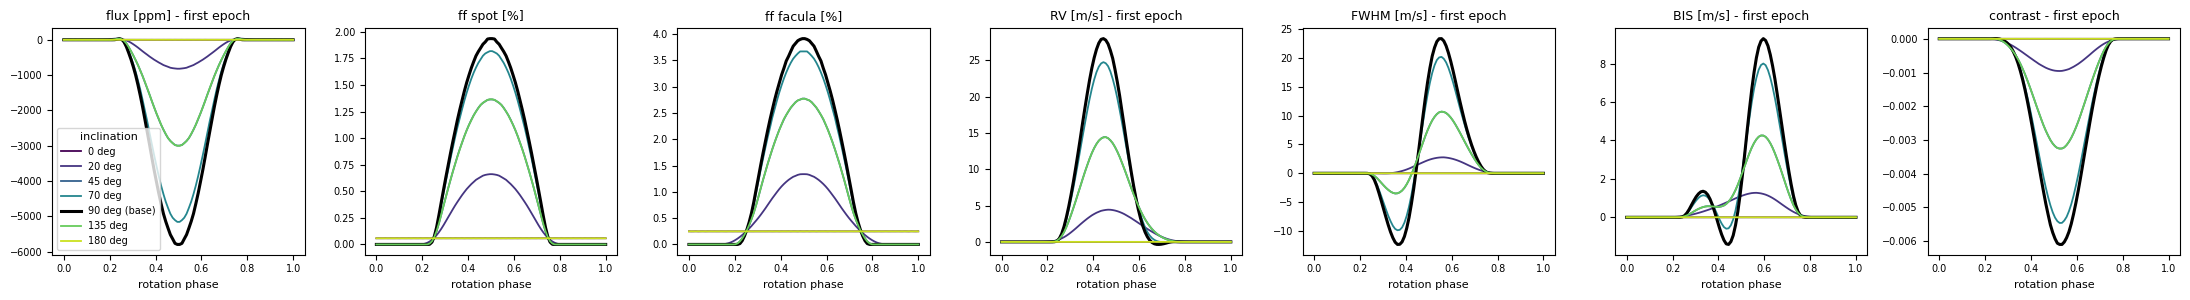

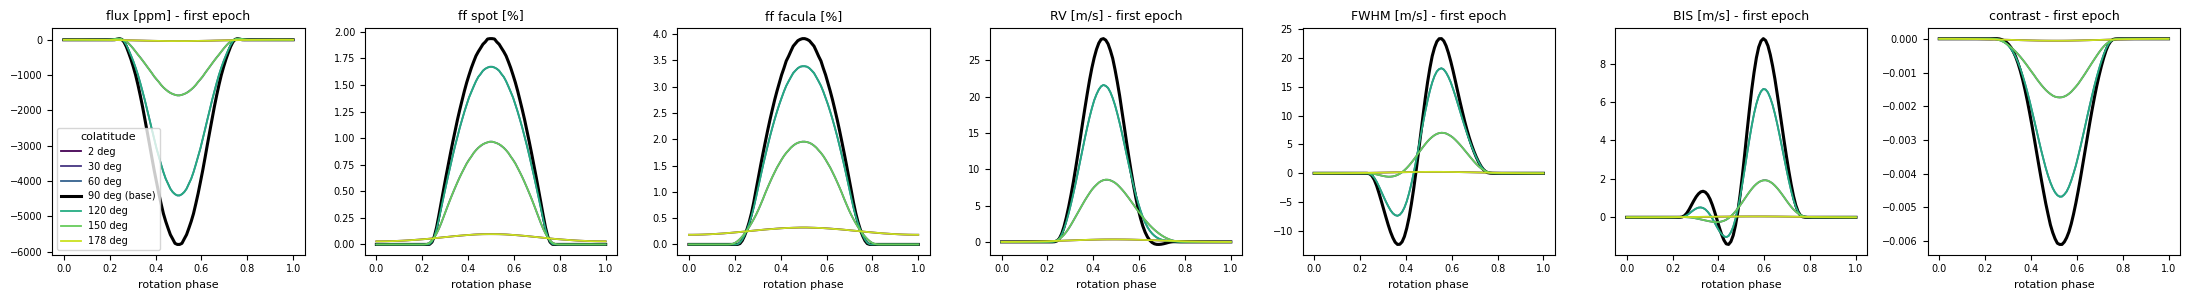

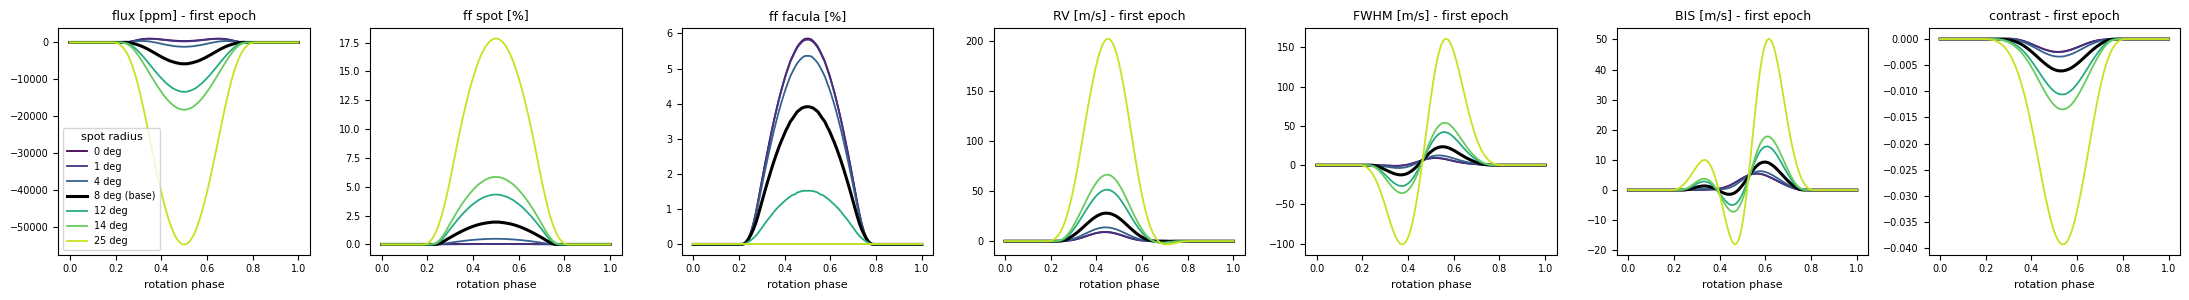

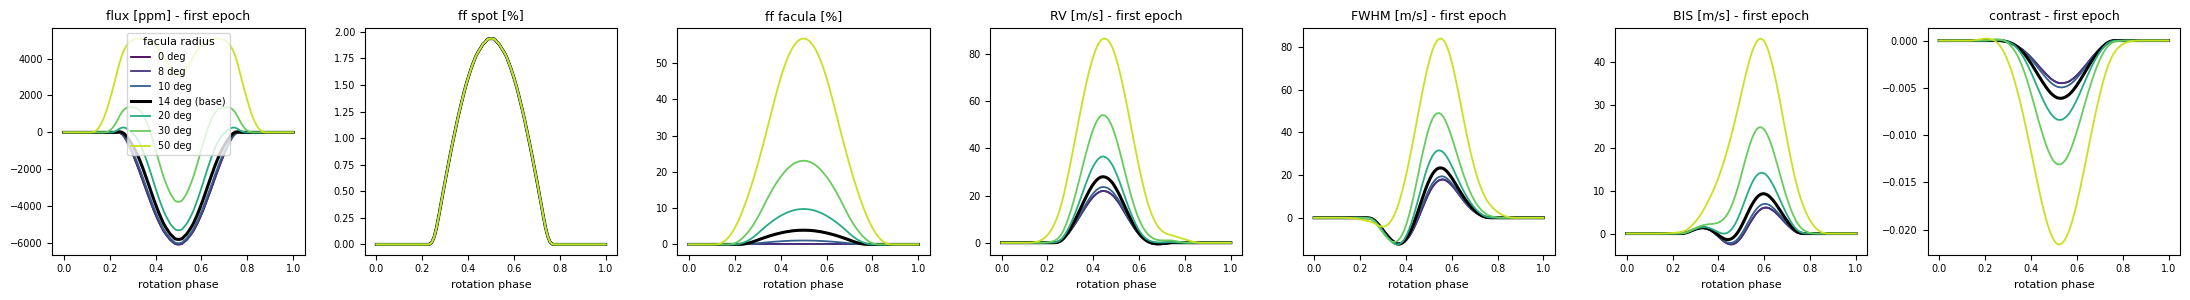

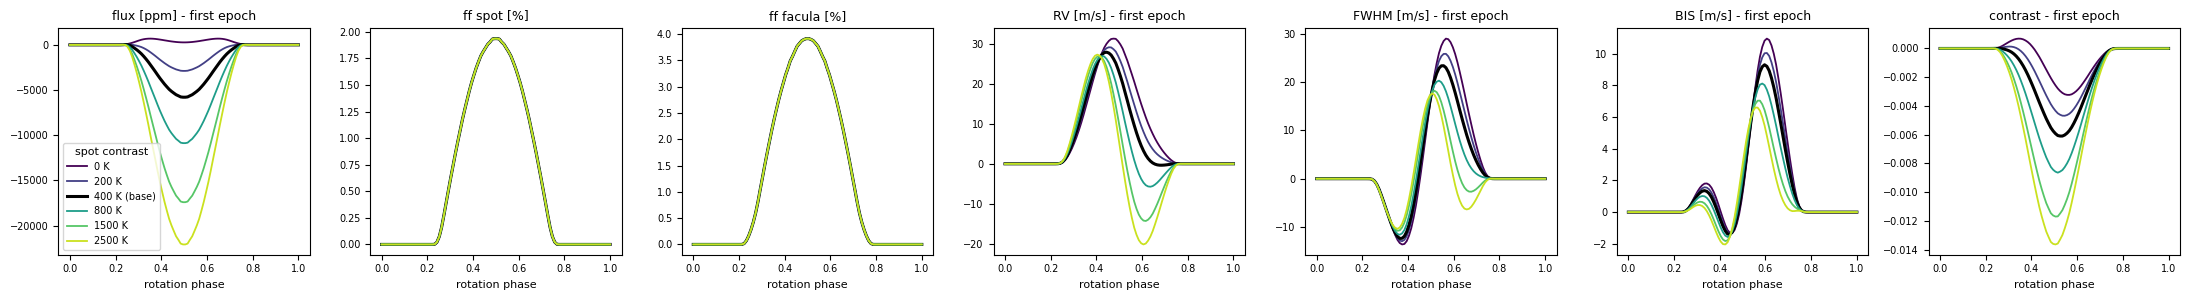

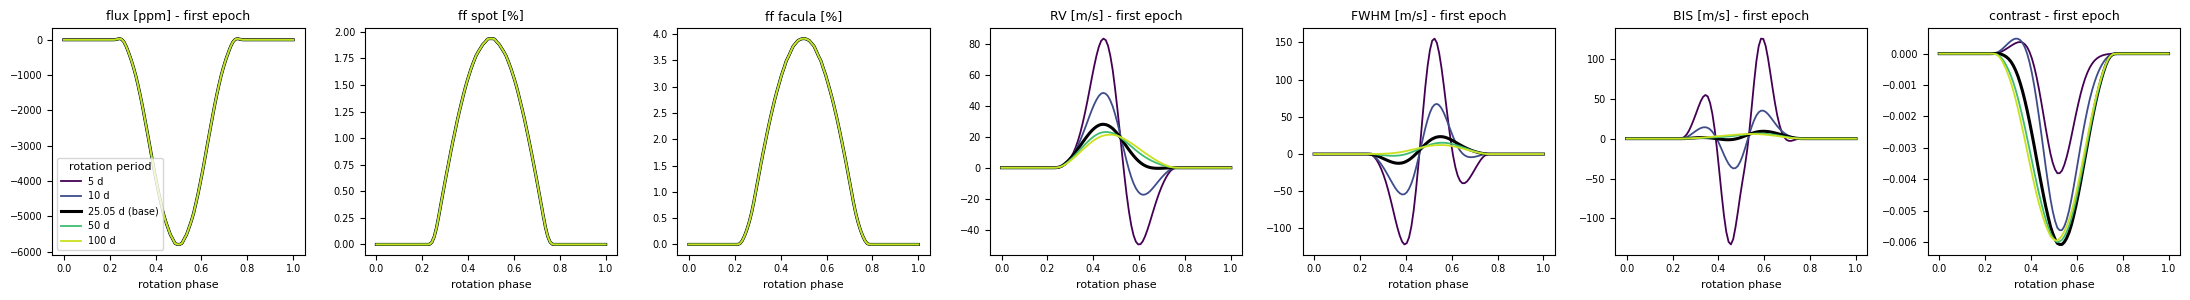

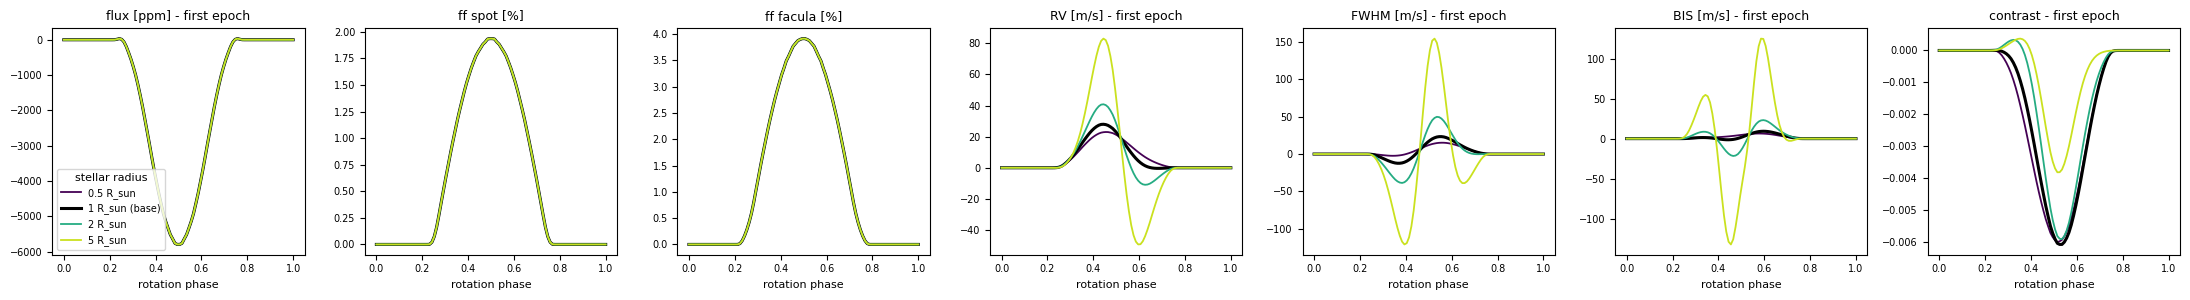

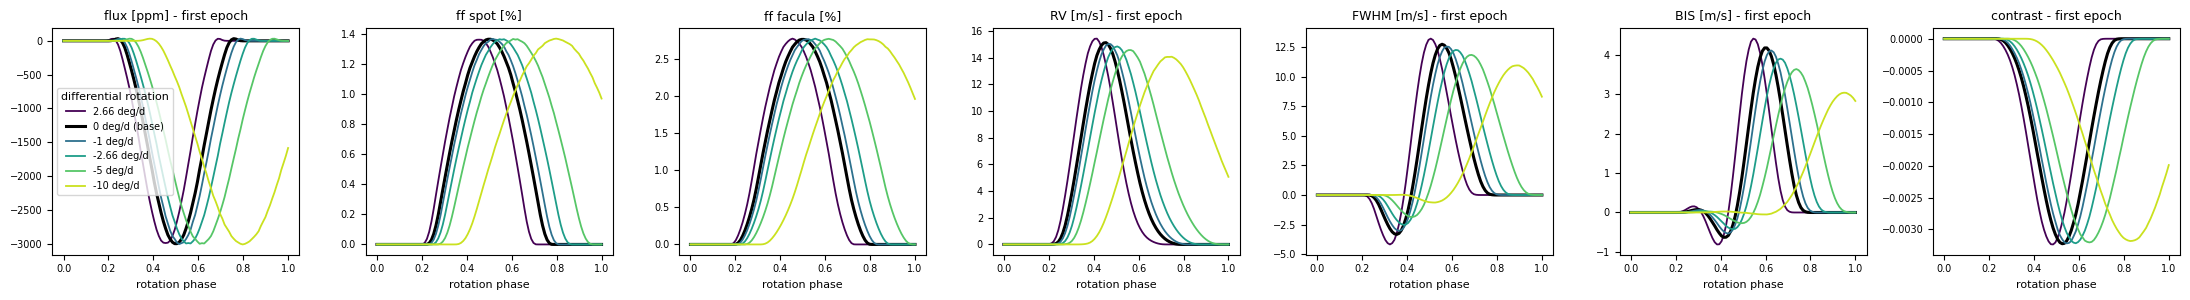

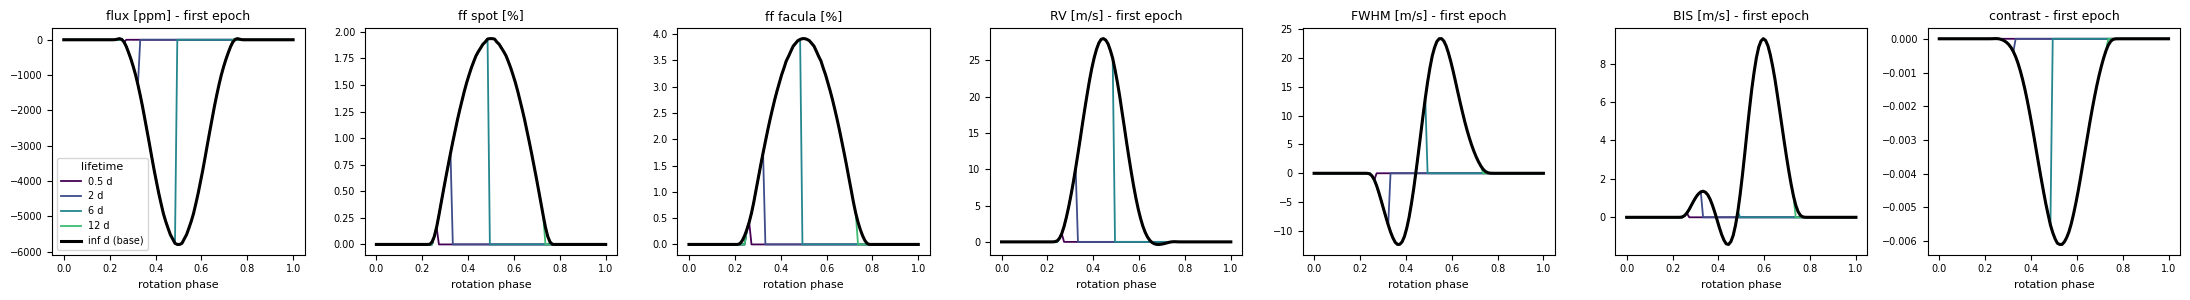

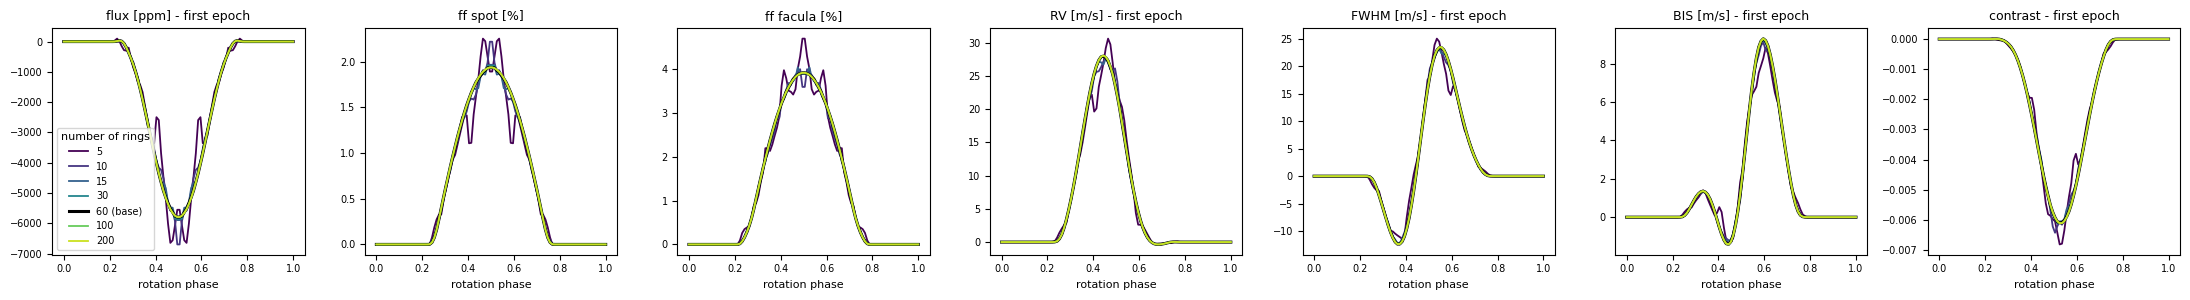

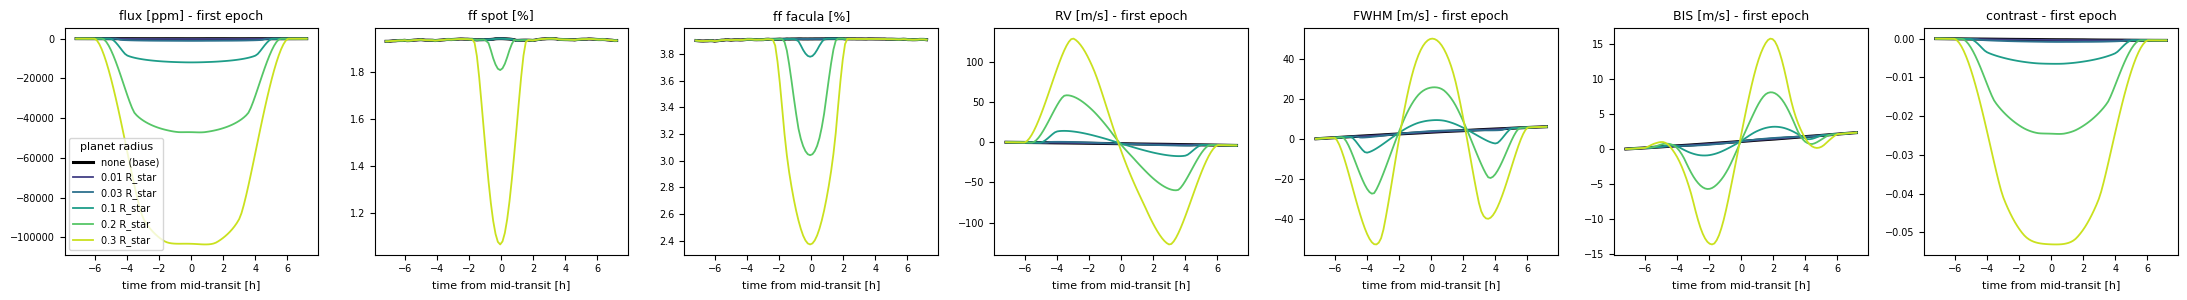

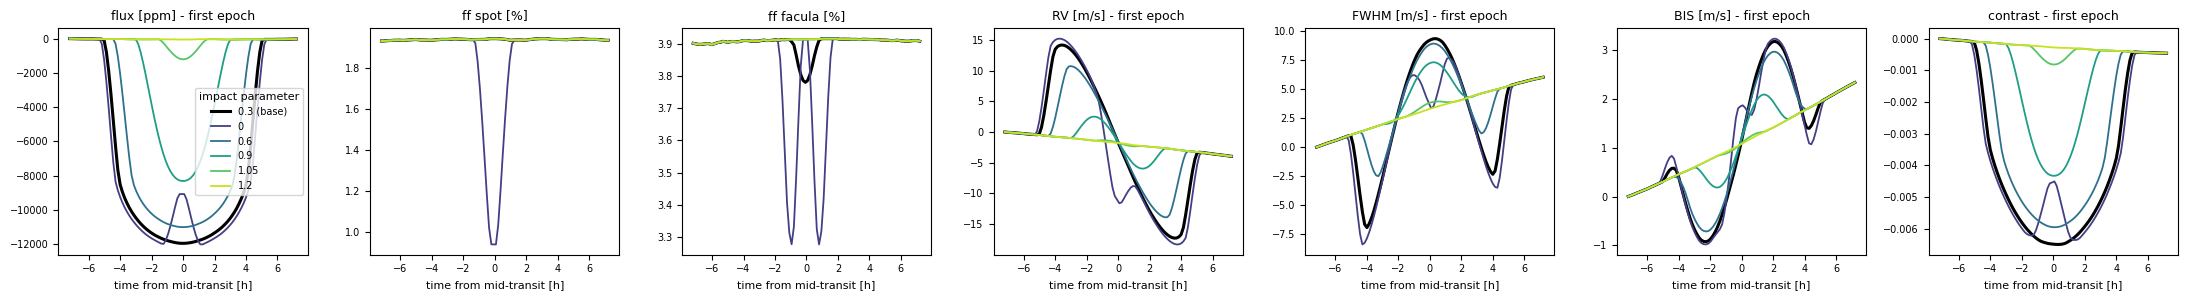

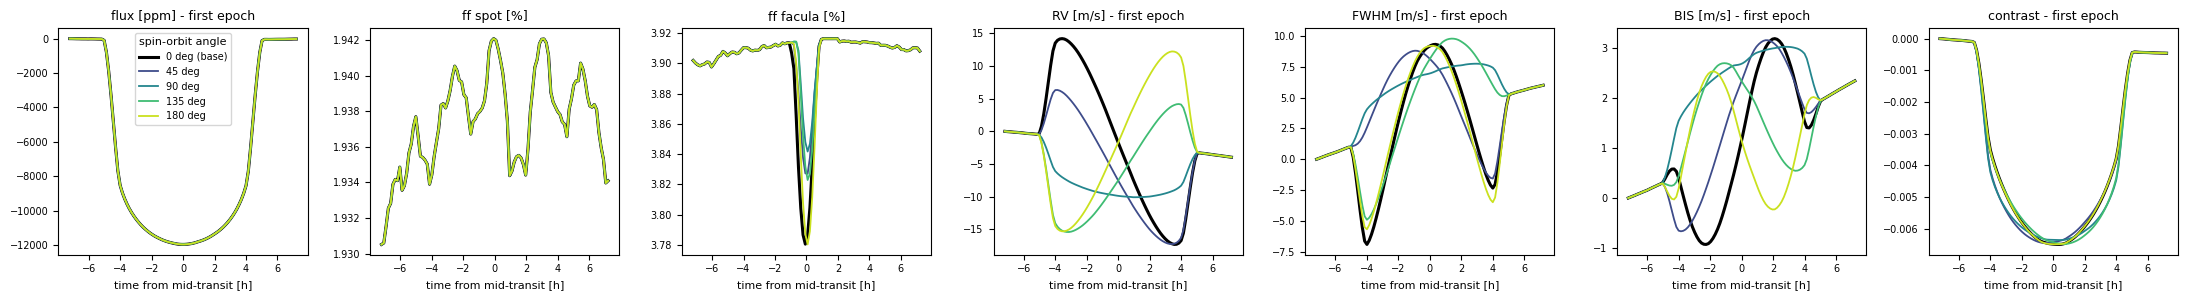

In [22]:
# every quantity relative to its value at the first epoch, except the filling factors (absolute, % of the disc)
quantities = [('flux', 'flux [ppm]'), ('ff_sp', 'ff spot [%]'), ('ff_fc', 'ff facula [%]'),
              ('rv', 'RV [m/s]'), ('fwhm', 'FWHM [m/s]'), ('bis', 'BIS [m/s]'), ('contrast', 'contrast')]
absolute = {'ff_sp', 'ff_fc'}

def label(key, v, unit):
    if v is None:
        return 'none'
    if key == 'period' and abs(v - P_rot) < 1e-9:
        return '%.2f %s' % (v, unit)
    return ('%g %s' % (v, unit)).strip()

def plot_sweep(name):
    key, values, unit = sweeps[name]
    res = sweep_results[name]
    colours = plt.cm.viridis(np.linspace(0, 0.92, len(values)))
    fig, axes = plt.subplots(1, len(quantities), figsize=(22, 3.1))
    for v, r, c in zip(values, res, colours):
        base_curve = v == base[key] or (v is None and base[key] is None)
        x = (r['t'] - t_transit) * 24 if name in planet_sweeps else r['t'] / (base['period'] if key != 'period' else v)
        for ax, (q, ylabel) in zip(axes, quantities):
            ax.plot(x, r[q] if q in absolute else r[q] - r[q][0], '-', color='k' if base_curve else c, lw=2.2 if base_curve else 1.3,
                    label=label(key, v, unit) + (' (base)' if base_curve else ''))
    for ax, (q, ylabel) in zip(axes, quantities):
        ax.set_title(ylabel if q in absolute else '%s - first epoch' % ylabel, fontsize=9)
        ax.set_xlabel('time from mid-transit [h]' if name in planet_sweeps else 'rotation phase', fontsize=8)
        ax.tick_params(labelsize=7)
    axes[0].legend(fontsize=7, title=name, title_fontsize=8)
    plt.tight_layout()
    plt.show()

for name in sweeps:
    plot_sweep(name)

**What the sweeps show** (one row per parameter above, the base case in black; the levels quoted for the FWHM and the contrast are those at t = 0, not visible in the figures, which show the changes since t = 0 for every quantity except the filling factors):

* **Inclination.** The modulation decreases with sin i and disappears pole-on (0° and 180°: the spot on the equator runs along the limb). The quiet-star FWHM follows v sin i, and the BIS and contrast levels change with it. 135° gives the curves of 45° (to ~0.4 %, the grid), because the regions are on the equator.
* **Colatitude.** North and south give the same curves (equator-on), and regions near the poles barely modulate.
* **Spot radius.** The flux dip and the RV, FWHM and BIS signals grow with the spot area. At 0° only the facula remains: a small brightening near the limb, and an RV from the suppression of the convective blueshift. From 14° the spot hides the whole facula (ff facula = 0).
* **Facula radius.** At 0° and 8° the facula is under the spot (same curves). Large faculae brighten the star near the limb (phases ~0.25 and ~0.75) and dominate the RV: the convective blueshift is suppressed, so the RV goes up, symmetrically.
* **Spot contrast.** The flux dip grows with ΔT. The filling factors don't change. The RV becomes more antisymmetric (rotational part of the spot) on top of the symmetric part of the facula.
* **Rotation period and stellar radius.** The light curve is the same (only v sin i changes, and the time axis is the rotation phase). The RV, BIS and FWHM signals grow with v sin i = 2πR/P: at 10 km/s (P = 5 d or R = 5 R☉) the RV signal is ~130 m/s and the BIS goes from −160 to +100 m/s, while the CCF is 2.2 times wider and half as deep. P = 5 d and R = 5 R☉ give the same CCF outputs (same v sin i).
* **Differential rotation** (regions at latitude 45°). Solar-like B < 0 slows the high latitudes, so the regions lag behind (later crossing) and the quiet CCF gets narrower. Anti-solar B > 0 does the opposite. With B = −10 deg/day the regions drift by ~135° in one rotation.
* **Lifetime.** With the constant law the regions appear and disappear in one step (at t = P/4 = phase 0.25, for the lifetime given).
* **Number of rings.** 5 and 10 rings show the cells (bumps). From 15 rings the curves are within ~2 % of the converged ones, and from 60 rings (the base case) within ~0.2 % (table below).
* **Planet.** The depth and the Rossiter–McLaughlin amplitude grow as R_p², down to the smallest planet (0.01 R★, smaller than a cell): the fraction of a cell covered by a planet is the exact projected area of the planet disc in the cell (`planet_coverage='area'`, the default; table below). A planet crossing the spot (impact 0 here) gives the bump of the spot occultation (ff spot drops). At impact 1.05 the transit is grazing, and at 1.2 there is none (the curves of no planet). The spin-orbit angle changes the shape of the RM effect: antisymmetric for 0° (aligned), reversed for 180° (retrograde), and one-sided for 90° (polar, the planet crosses only one side of the rotation-velocity field).

**Small planets: exact coverage of the cells.** The old StarSim covered a cell with a linear ramp in the distance between the centres of the cell and of the planet, over the width of the cell: a cell whose centre is under the planet was about half covered whatever the radius of the planet, so the planets smaller than a cell were much too deep. SunSim now integrates the exact projected area of the planet disc inside every cell (an annular sector on the sky; `nbspectra._planet_cell_area_nb`, checked against the pixels of a 4096 × 4096 image). `StarSim(..., planet_coverage='ramp')` gives the old formula (used by `simulate_old_config(..., reproduce_old_bugs=True)`; test cases `phx_small_planet` and `fixed_*planet*` of section 10). Below: transit depth / R_p² on a uniform disc (no limb darkening), b = 0.3, which must be 1. The exact coverage costs at most ~1.5 times the old one for the epochs in transit (100 rings), nothing outside the transits.

In [23]:
from sunsim import planet as Planet

def uniform(scale):
    wv = np.linspace(5000, 5100, 201)
    return {mu: {'wav': wv, 'intensity': scale * np.ones_like(wv)} for mu in (0.05, 0.5, 1.0)}

rows = []
for coverage in ('ramp', 'area'):
    for rp in (0.003, 0.01, 0.03, 0.1, 0.2):
        row = {'planet_coverage': coverage, 'R_p [R_star]': rp}
        for n in (5, 15, 30, 60, 200):
            g = []
            for scale in (1.0, 0.5, 1.1):
                fg = flux_grid(n, uniform(scale), 'x', None, 5000, 5100)
                fg.built_grid()
                g.append(fg)
            pl = Planet(planet_period=P_rot, planet_transit_t0=0.0, planet_radius=rp, planet_semi_major_axis=20.0,
                        planet_impact_param=0.3)
            ss = StarSim(np.linspace(-0.05, 0.05, 101), n, inclination=0.0, rotation_period=P_rot, planet=pl,
                         planet_coverage=coverage, flux_grid_qp=g[0].grid, flux_grid_sp=g[1].grid, flux_grid_fc=g[2].grid)
            with contextlib.redirect_stdout(io.StringIO()):
                ss.generate_timeseries(verbose=False)
            row['%d rings' % n] = np.mean(1 - ss.flux_var / g[0].total_brightness) / rp**2
        rows.append(row)
pd.options.display.float_format = '{:.3f}'.format
pd.DataFrame(rows).set_index(['planet_coverage', 'R_p [R_star]'])

5 rings  15 rings  30 rings  60 rings  200 rings
planet_coverage R_p [R_star]                                                  
ramp            0.003         626.024    67.234    18.379     5.317      1.514
                0.010          63.571     8.219     3.062     1.539      1.045
                0.030           9.685     1.951     1.226     1.058      1.006
                0.100           2.016     1.088     1.023     1.006      1.001
                0.200           1.204     1.013     1.005     1.002      1.001
area            0.003           1.001     1.000     1.001     1.001      1.001
                0.010           1.001     1.000     1.001     1.001      1.001
                0.030           1.001     1.000     1.001     1.001      1.001
                0.100           1.001     1.000     1.001     1.001      1.001
                0.200           1.000     1.000     1.001     1.001      1.001

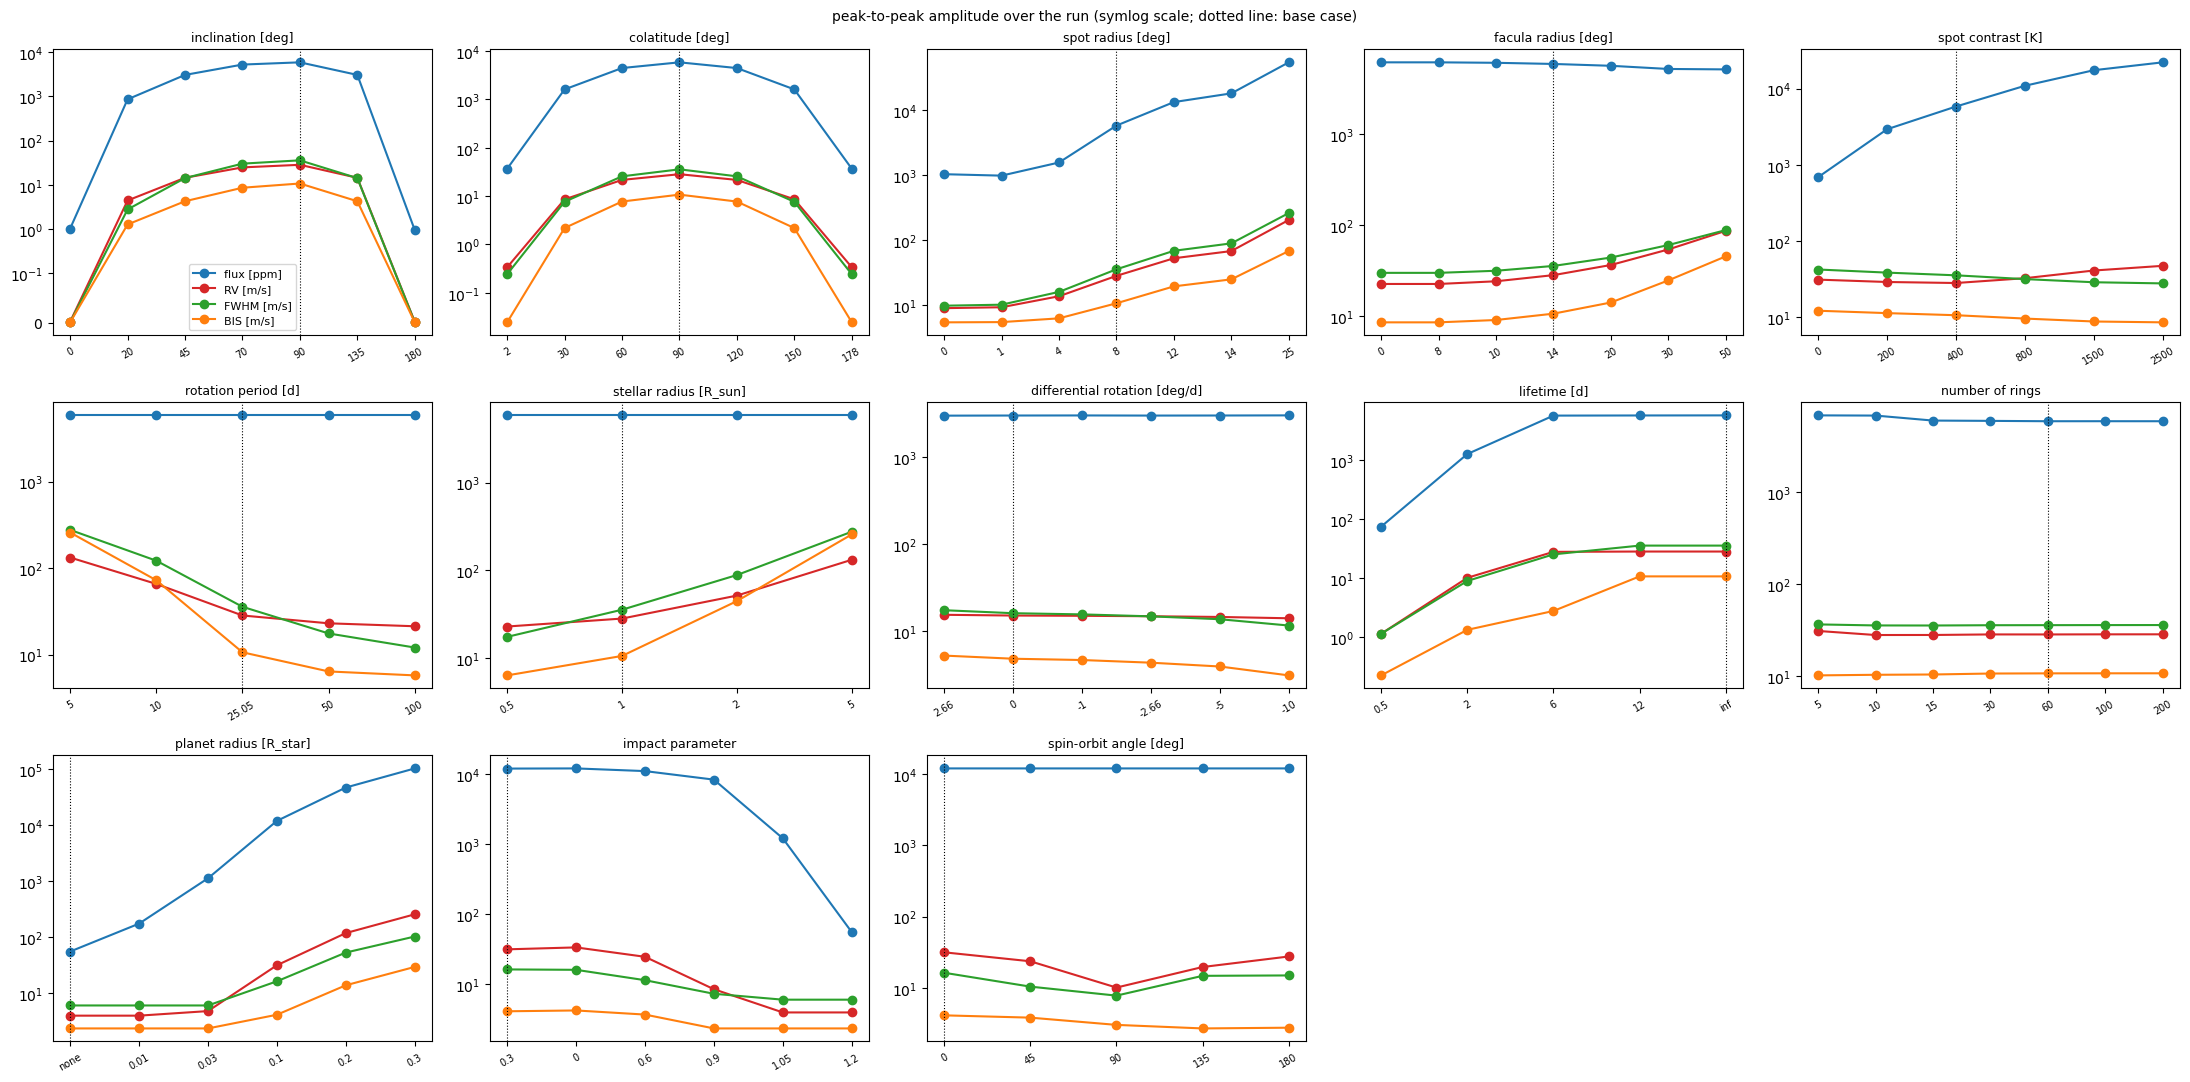

In [24]:
# peak-to-peak amplitude of every output against every parameter (the base value with a black dot)
fig, axes = plt.subplots(3, 5, figsize=(22, 11))
amp_q = [('flux', 'flux [ppm]', 'C0'), ('rv', 'RV [m/s]', 'C3'), ('fwhm', 'FWHM [m/s]', 'C2'), ('bis', 'BIS [m/s]', 'C1')]
for ax, name in zip(axes.flat, sweeps):
    key, values, unit = sweeps[name]
    xs = np.arange(len(values))
    for q, ql, colour in amp_q:
        amp = [np.ptp(r[q]) for r in sweep_results[name]]
        ax.plot(xs, amp, 'o-', color=colour, label=ql)
    ax.set_yscale('symlog', linthresh=0.1)
    ax.set_xticks(xs, [label(key, v, '') for v in values], fontsize=7, rotation=30)
    ax.set_title('%s [%s]' % (name, unit) if unit else name, fontsize=9)
    ib = [i for i, v in enumerate(values) if v == base[key] or (v is None and base[key] is None)]
    for i in ib:
        ax.axvline(i, color='k', lw=0.8, ls=':')
for ax in axes.flat[len(sweeps):]:
    ax.set_axis_off()
axes.flat[0].legend(fontsize=8)
fig.suptitle('peak-to-peak amplitude over the run (symlog scale; dotted line: base case)', fontsize=10)
plt.tight_layout()
plt.show()

**Consistency checks.** These are cases whose result is known in advance: a symmetry, a limit, or the base case in every sweep. They work as tests of the optimized code on extreme parameters, without the old version.

In [25]:
# consistency checks of the sweeps: cases whose result is known in advance.
# 'exact': must hold to the rounding. 'grid': holds for the star but not cell by cell (the regions cross the cells of
# the grid differently, see below): the value is relative to the amplitude of the base case, and must be < 2 % (~0.2 % with the 60 rings of the base case).
sw = lambda name: sweeps[name][1]
run_of = lambda name, v: sweep_results[name][sw(name).index(v)]
base_run = run_of('inclination', 90)
amp = {q: np.ptp(base_run[q]) for q in ('flux', 'rv')}
diff = lambda a, b, q: np.max(np.abs(a[q] - b[q]))

checks = [
    ('pole-on (i = 0): no modulation of the flux', np.ptp(run_of('inclination', 0)['flux']) / amp['flux'], 'grid'),
    ('pole-on (i = 0): no modulation of the RV', np.ptp(run_of('inclination', 0)['rv']) / amp['rv'], 'grid'),
    ('i = 0 and i = 180 (both poles): the same flux', diff(run_of('inclination', 0), run_of('inclination', 180), 'flux') / amp['flux'], 'grid'),
    ('equator-on: colatitude 30 = 150 (flux)', diff(run_of('colatitude', 30), run_of('colatitude', 150), 'flux') / amp['flux'], 'grid'),
    ('equator-on: colatitude 30 = 150 (RV)', diff(run_of('colatitude', 30), run_of('colatitude', 150), 'rv') / amp['rv'], 'grid'),
    ('facula radius 8 = spot radius: no facula visible [%]', np.max(run_of('facula radius', 8)['ff_fc']), 'exact'),
    ('facula radius 0 and 8: the same flux [ppm]', diff(run_of('facula radius', 0), run_of('facula radius', 8), 'flux'), 'exact'),
    ('spot radius 14 = facula radius: no facula visible [%]', np.max(run_of('spot radius', 14)['ff_fc']), 'exact'),
    ('spot radius 0: no spot [%]', np.max(run_of('spot radius', 0)['ff_sp']), 'exact'),
    ('impact 1.2: no transit, the flux without planet [ppm]', diff(run_of('impact parameter', 1.2), run_of('planet radius', None), 'flux'), 'exact'),
    ('lifetime: no region before it appears [%]',
     max(np.max(r['ff_sp'][r['t'] < base['period'] / 4 - 1e-9]) for r in sweep_results['lifetime'][:-1]), 'exact'),
    ('base case: the same in every sweep [ppm]',
     max(diff(run_of(n, base[sweeps[n][0]]), base_run, 'flux') for n in sweeps
         if n not in planet_sweeps | wide_rv_sweeps | {'differential rotation'} and base[sweeps[n][0]] in sw(n)), 'exact'),
]
table = pd.DataFrame([{'check': c, 'kind': kind, 'value': '%.3g %%' % (100 * v) if kind == 'grid' else '%.3g' % v,
                       'tolerance': '2 % of the base amplitude' if kind == 'grid' else '1e-6',
                       'ok': 'yes' if v < (0.02 if kind == 'grid' else 1e-6) else 'NO'} for c, v, kind in checks]).set_index('check')
print('%d checks, %d failed' % (len(table), np.sum(table['ok'] == 'NO')))
table

12 checks, 0 failed


,kind,value,tolerance,ok
check,,,,
pole-on (i = 0): no modulation of the flux,grid,0.0177 %,2 % of the base amplitude,yes
pole-on (i = 0): no modulation of the RV,grid,0.00617 %,2 % of the base amplitude,yes
i = 0 and i = 180 (both poles): the same flux,grid,0.017 %,2 % of the base amplitude,yes
equator-on: colatitude 30 = 150 (flux),grid,0.201 %,2 % of the base amplitude,yes
equator-on: colatitude 30 = 150 (RV),grid,0.112 %,2 % of the base amplitude,yes
facula radius 8 = spot radius: no facula visible [%],exact,0,1e-6,yes
facula radius 0 and 8: the same flux [ppm],exact,0,1e-6,yes
spot radius 14 = facula radius: no facula visible [%],exact,0,1e-6,yes
spot radius 0: no spot [%],exact,0,1e-6,yes


The `grid` checks are not exact because of the grid: a region near the limb (pole-on, the equatorial spot runs along the limb) or off the equator meets the cells of the rings differently as it moves, while the true star is symmetric. These differences decrease with the number of rings, as shown below (the same checks for 15 to 200 rings, in % of the amplitude of the base case with the same number of rings), together with the convergence of the amplitudes themselves: with 15 rings, the amplitudes of the light curve and of the RV of this case are within ~2 % of the converged values, and the symmetries hold to ~1 %.

In [26]:
rows = []
for n in (15, 30, 60, 100, 200):
    b = sweep_run('convergence', n_rings=n)
    pole = [sweep_run('convergence', n_rings=n, inclination=i) for i in (0, 180)]
    north, south = (sweep_run('convergence', n_rings=n, colatitude=c) for c in (30, 150))
    rows.append({'rings': n,
                 'flux amplitude [ppm]': np.ptp(b['flux']), 'RV amplitude [m/s]': np.ptp(b['rv']),
                 'pole-on flux modulation [%]': 100 * np.ptp(pole[0]['flux']) / np.ptp(b['flux']),
                 'pole-on RV modulation [%]': 100 * np.ptp(pole[0]['rv']) / np.ptp(b['rv']),
                 'i = 0 vs 180 flux [%]': 100 * np.max(np.abs(pole[0]['flux'] - pole[1]['flux'])) / np.ptp(b['flux']),
                 'colat 30 vs 150 flux [%]': 100 * np.max(np.abs(north['flux'] - south['flux'])) / np.ptp(b['flux']),
                 'colat 30 vs 150 RV [%]': 100 * np.max(np.abs(north['rv'] - south['rv'])) / np.ptp(b['rv'])})
pd.options.display.float_format = '{:.3g}'.format
pd.DataFrame(rows).set_index('rings')

,flux amplitude [ppm],RV amplitude [m/s],pole-on flux modulation [%],pole-on RV modulation [%],i = 0 vs 180 flux [%],colat 30 vs 150 flux [%],colat 30 vs 150 RV [%]
rings,,,,,,,
15,5.92e+03,27.9,0.272,0.0953,0.241,1.13,0.828
30,5.88e+03,28.3,0.0836,0.0179,0.0444,0.817,0.325
60,5.82e+03,28.3,0.0177,0.00617,0.017,0.201,0.112
100,5.83e+03,28.4,0.0104,0.00229,0.0104,0.112,0.0535
200,5.82e+03,28.4,0.00229,0.00105,0.0023,0.0359,0.0216


## 12. 2D maps: the 89 real SDO epochs

The same comparison for the **2D maps**: the real SDO maps of spots and faculae of the Google Drive folder `maps_active_2015_09_12_ccf_notnorm` (89 epochs, one per day, ~950 × 950 pixels, binary masks as text files, 18 MB each), MURaM low resolution spectra, 15 rings, light curve and RV, FWHM, BIS, contrast (the configuration of the tests of section 10).

| version | what runs |
|---|---|
| old StarSim | `StarSim(conf)` (reads the 178 maps), `compute_forward(['lc'])`, `compute_forward(['rv', 'bis', 'fwhm', 'contrast'])` |
| SunSim, old physics | `simulate_old_config(conf, reproduce_old_bugs=True)`: the old treatment of the faculae of the maps (as spots in photometry, as quiet photosphere in the CCFs, section 10) and the old projection, to compare the outputs number by number |
| SunSim | `simulate_old_config(conf)`: the faculae with their own MURaM spectra, the projection of `active_region_mask` |
| SunSim, maps as .npy | the same with the maps saved once as `uint8` `.npy` (38 s, in `benchmarks/work/`, not in the folder of the maps) |

All of them read the maps themselves (nothing is cached between the runs). Every run is a **new process** (imports included); the time of every step and the **peak memory of the process** are measured, 3 runs per version (`benchmarks/sdo_benchmark.py`; `python benchmarks/sdo_benchmark.py all --repeat 3` runs everything again, ~15 min, mostly the old code). The results are read here from `benchmarks/results/`. The peak memory of the old code changes a lot from run to run (656-1449 MB): macOS compresses the memory of a process when the computer is short of free memory, as it was here; the medians are given.

In [27]:
import glob, json, re
bench_dir = os.path.join(REPO, 'benchmarks')
labels = {'old': 'old StarSim', 'new_old_bugs': 'SunSim, old physics', 'new': 'SunSim',
          'new_npy': 'SunSim, maps as .npy'}
runs = {}
for v in labels:
    files = sorted(f for f in glob.glob(os.path.join(bench_dir, 'results', '%s_*.npz.json' % v))
                   if re.fullmatch(r'%s_\d+\.npz\.json' % v, os.path.basename(f)))      # new_0, not new_npy_0
    if files:
        runs[v] = [json.load(open(f)) for f in files]
missing = [v for v in labels if v not in runs]
if missing:
    print('no results for %s: run  python benchmarks/sdo_benchmark.py run %s --repeat 3' % (missing, ' '.join(missing)))

rows = []
for v, rs in runs.items():
    tot = np.array([r['steps']['total'] for r in rs])
    ram = np.array([r['peak_rss_mb'] for r in rs])
    rows.append({'version': labels[v], 'runs': len(rs), 'time [s] (median)': np.median(tot),
                 'time [s] (min-max)': '%.1f-%.1f' % (tot.min(), tot.max()), 'peak memory [MB]': np.median(ram)})
table = pd.DataFrame(rows).set_index('version')
t_old, m_old = table.loc['old StarSim', 'time [s] (median)'], table.loc['old StarSim', 'peak memory [MB]']
table['speed-up'] = t_old / table['time [s] (median)']
table['memory / old'] = table['peak memory [MB]'] / m_old
pd.options.display.float_format = '{:.3g}'.format
table

,runs,time [s] (median),time [s] (min-max),peak memory [MB],speed-up,memory / old
version,,,,,,
old StarSim,3,244,185.7-313.5,1.18e+03,1,1
"SunSim, old physics",3,18.3,15.3-22.1,688,13.4,0.584
SunSim,3,19.3,16.7-20.0,635,12.7,0.539
"SunSim, maps as .npy",3,1.39,0.9-3.7,416,175,0.353


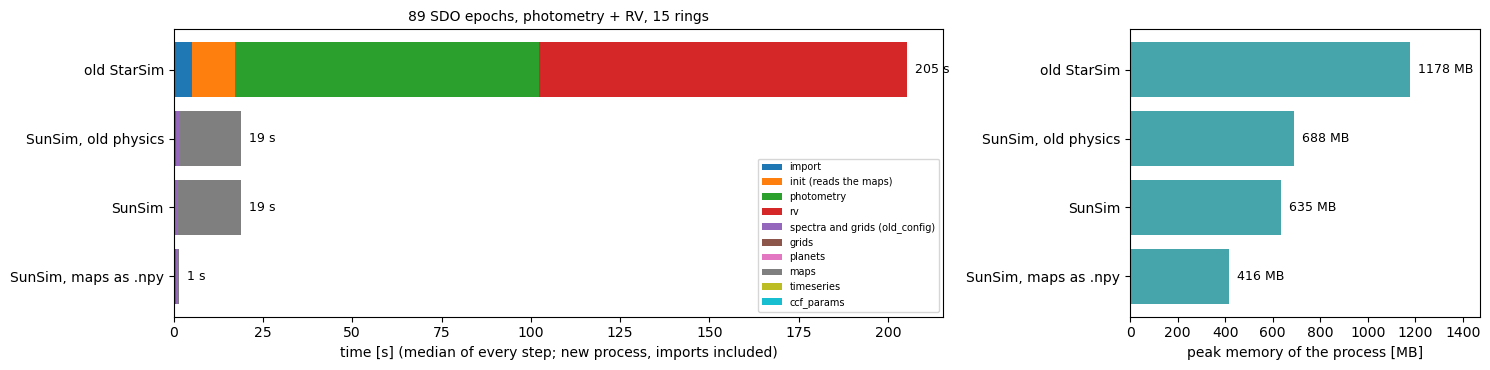

In [28]:
# time of every step (median of the runs) and peak memory
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={'width_ratios': [2.2, 1]})
order = [v for v in labels if v in runs]
colours = plt.cm.tab10(np.arange(10))
step_colour = {}
for i, v in enumerate(order):
    steps = {k: np.median([r['steps'][k] for r in runs[v]]) for k in runs[v][0]['steps'] if k != 'total'}
    left = 0.0
    for k, dt in steps.items():
        c = step_colour.setdefault(k, colours[len(step_colour) % 10])
        ax1.barh(i, dt, left=left, color=c, label=k if k not in ax1.get_legend_handles_labels()[1] else None)
        left += dt
    ax1.text(left, i, '  %.0f s' % left, va='center', fontsize=9)
ax1.set_yticks(range(len(order)), [labels[v] for v in order])
ax1.invert_yaxis()
ax1.set_xlabel('time [s] (median of every step; new process, imports included)')
ax1.legend(fontsize=7, loc='lower right')
ax1.set_title('89 SDO epochs, photometry + RV, 15 rings', fontsize=10)
mem = [np.median([r['peak_rss_mb'] for r in runs[v]]) for v in order]
ax2.barh(range(len(order)), mem, color='#45a5aa')
for i, m in enumerate(mem):
    ax2.text(m, i, '  %.0f MB' % m, va='center', fontsize=9)
ax2.set_yticks(range(len(order)), [labels[v] for v in order])
ax2.invert_yaxis()
ax2.set_xlabel('peak memory of the process [MB]')
ax2.set_xlim(0, 1.25 * max(mem))
plt.tight_layout()
plt.show()

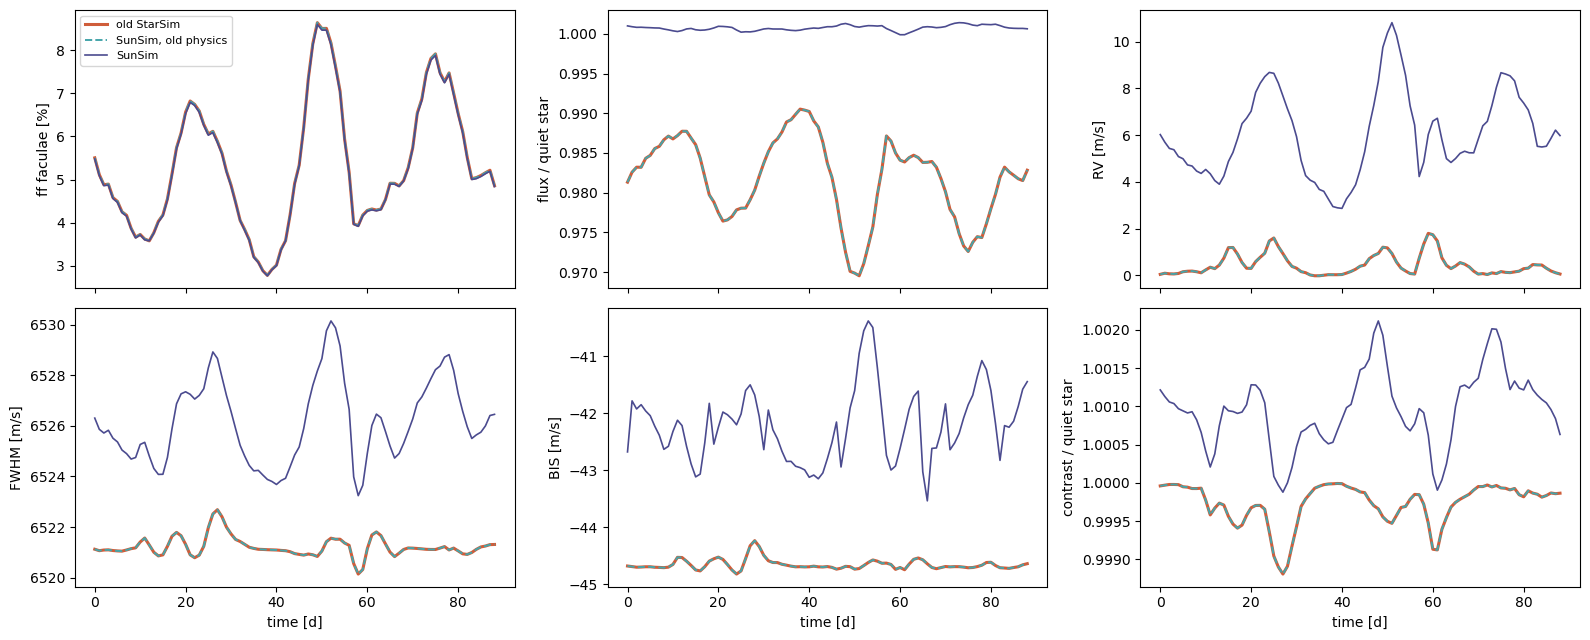

,max |old - SunSim old physics|,max |old - SunSim|,amplitude (old),amplitude (SunSim)
quantity,,,,
ff_fc,0,0.0417,5.87,5.84
lc,4.11e-15,0.0313,0.021,0.00152
rv,1.41e-06,9.87,1.81,7.94
fwhm,1.51e-05,8.59,2.55,6.91
bis,1.3e-11,4.24,0.587,3.16
contrast,8.24e-10,0.00245,0.00118,0.00224


In [29]:
# outputs: the old code, SunSim with the old physics (must be the same) and SunSim with its own physics
out = {v: dict(np.load(os.path.join(bench_dir, 'results', '%s_0.npz' % v))) for v in runs}
quantities = [('ff_fc', 'ff faculae [%]'), ('lc', 'flux / quiet star'), ('rv', 'RV [m/s]'), ('fwhm', 'FWHM [m/s]'),
              ('bis', 'BIS [m/s]'), ('contrast', 'contrast / quiet star')]
style = {'old': ('-', 2.2, '#cf5d3a'), 'new_old_bugs': ('--', 1.4, '#45a5aa'), 'new': ('-', 1.2, '#4b4b8f')}
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5), sharex=True)
for ax, (q, label) in zip(axes.flat, quantities):
    for v, (ls, lw, c) in style.items():
        if v in out:
            ax.plot(out[v]['time'], out[v][q], ls, lw=lw, color=c, label=labels[v])
    ax.set_ylabel(label)
axes[0, 0].legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel('time [d]')
plt.tight_layout()
plt.show()

diff = pd.DataFrame([{'quantity': q,
                      'max |old - SunSim old physics|': np.max(np.abs(out['old'][q] - out['new_old_bugs'][q])),
                      'max |old - SunSim|': np.max(np.abs(out['old'][q] - out['new'][q])),
                      'amplitude (old)': np.ptp(out['old'][q]), 'amplitude (SunSim)': np.ptp(out['new'][q])}
                     for q, _ in quantities]).set_index('quantity')
pd.options.display.float_format = '{:.3g}'.format
diff

**Results.**

* **Same outputs.** SunSim with the old physics gives the numbers of the old code: light curve to 4e-15, RV to 1.4e-6 m/s, FWHM to 1.5e-5 m/s, BIS to 1e-11 m/s, filling factors identical. With its own physics (faculae with their own spectra) the light curve is ~1.000 instead of ~0.98 and the RV 3-11 m/s instead of 0-2 m/s (the faculae issue of section 10).
* **Time.** The old code takes 186-314 s (median 244 s): 12-29 s to read the maps, then 72-107 s for the light curve and 99-210 s for the RV (a Python loop over the epochs, the projection of every map recomputed at every epoch, the grids rebuilt in every `compute_forward`). SunSim takes 17-20 s, and **~95 % of it is reading the 178 text files** (3.2 GB of text, from Google Drive): the simulation itself (89 epochs, light curve and CCFs together, then the 89 CCF fits) takes **~0.05 s**, the spectra and the grids ~0.5 s. With the maps as `.npy` the whole run takes **~1.4 s (175× faster than the old code)**.
* **Memory.** The old code keeps the 178 maps in memory as float64 (~1.3 GB): peak 0.66-1.45 GB. SunSim reads a few maps at a time (4 threads) and keeps only the filling factors of the cells: 0.6-0.7 GB with the text maps (mostly the text parser), 0.4 GB with `.npy` maps (most of it the imported libraries: NumPy, Numba, astropy).
* **To do with your own maps**: convert them once to `.npy` (`active_region_mask(folder, cache_npy=True)` writes a `.npy` next to every text map the first time, or save `uint8` masks yourself); then a run on the 89 epochs takes ~1 s instead of ~20 s, and the number of rings, the spectra or the mode can be changed at no cost (`cache_filling_factors=True` also keeps the filling factors of every epoch).

## 13. Clean up

The temporary folder only holds the configuration files written for the old version.

In [30]:
shutil.rmtree(work_dir, ignore_errors=True)
print('deleted', work_dir)

deleted /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/sunsim_benchmark_2k3kbxx1
